# Sales Data Cleaning & Exploratory Data Analysis

**Role:** Data Analyst  |  **Tools:** Python, Pandas, Matplotlib/Seaborn, Excel

## Business scenario
A retail company exported its transaction records from several systems and sent us a **messy sales file**
(`data/raw_sales_data.csv`). Management needs (1) a trustworthy, analysis-ready dataset and
(2) clear answers about sales performance: revenue, best sellers, seasonality, regions and payment habits.

## What this notebook does
1. **Inspect** the raw file and build a register of data-quality problems (*before* statistics).
2. **Clean** it step by step. Every decision is explained, and **no suspicious record is silently deleted**:
   removed duplicates and quarantined records are written to `data/flagged_records.csv` with the reason.
3. Report **before vs. after** data-quality statistics and reconcile every raw row.
4. Run the **exploratory analysis** (KPIs, products, categories, months, regions, payment methods) and draw the charts.
5. Export the **Excel workbook** and the **written report**, then run automated **QA checks** that tie every reported number back to the cleaned data.

> The dataset is synthetic (generated by `src/generate_raw_data.py`, seeded for reproducibility) but built to mimic real export problems.
> One row = one order line (one product per order), so *orders* = distinct `Order_ID`s.

## 0. Setup and business rules
Thresholds are collected in one place so every assumption is visible and easy to change.

In [1]:
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# --- project paths (works whether the notebook is run from notebooks/ or from the project root) ---
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

RAW_CSV = ROOT / "data" / "raw_sales_data.csv"
CLEAN_CSV = ROOT / "data" / "cleaned_sales_data.csv"
FLAGGED_CSV = ROOT / "data" / "flagged_records.csv"
XLSX_PATH = ROOT / "output" / "sales_analysis.xlsx"
CHART_DIR = ROOT / "output" / "charts"
REPORT_MD = ROOT / "reports" / "analysis_report.md"
CHART_DIR.mkdir(parents=True, exist_ok=True)

# --- business rules / assumptions -------------------------------------------------------------
PLACEHOLDERS = {"", "n/a", "na", "null", "none", "nan", "--", "-"}   # text that really means "missing"
MAX_QTY = 100                      # a single order line above this many units is treated as invalid (e.g. 999 sentinel)
PRICE_UPPER_MULT = 3.0             # unit price above 3x the product's typical price is implausible
PRICE_RECOVERY_BAND = (0.85, 1.15) # a price rebuilt from Total/Qty must be within +-15% of the product's typical price
DATE_FORMATS = ["%Y-%m-%d", "%d/%m/%Y", "%d-%b-%Y", "%B %d, %Y", "%Y/%m/%d"]  # slash dates are DAY/MONTH/YEAR (verified below)
VALID_DATE_MIN, VALID_DATE_MAX = pd.Timestamp("2020-01-01"), pd.Timestamp("2025-12-31")  # data covers FY2025
UNKNOWN = {"Customer_ID": "UNKNOWN", "Region": "Unknown", "Payment_Method": "Unknown",
           "Product": "Unknown Product", "Category": "Unknown Category"}
TEXT_COLS = ["Product", "Category", "Region", "Payment_Method"]
FINAL_COLS = ["Order_ID", "Order_Date", "Customer_ID", "Product", "Category",
              "Quantity", "Unit_Price", "Total_Sales", "Region", "Payment_Method"]

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print(f"pandas {pd.__version__} | numpy {np.__version__} | project root: {ROOT.name}/")

pandas 3.0.5 | numpy 2.5.3 | project root: Sales_Data_Analysis/


### Helper functions
Small, reusable functions keep the cleaning steps below short and readable.

In [2]:
def is_placeholder(series: pd.Series) -> pd.Series:
    """True where a text cell is empty or a placeholder such as 'N/A', 'NULL' or '--'."""
    return series.str.strip().str.lower().isin(PLACEHOLDERS)


def normalize_text(series: pd.Series) -> pd.Series:
    """Trim, collapse repeated spaces, and turn placeholders into real missing values."""
    cleaned = series.str.strip().str.replace(r"\s+", " ", regex=True)
    return cleaned.mask(cleaned.str.lower().isin(PLACEHOLDERS))


def normalize_id(series: pd.Series, prefix: str, digits: int) -> pd.Series:
    """'  cust0012 ' -> 'CUST-0012'.  Anything that still does not match the pattern is reported later."""
    s = normalize_text(series).str.upper().str.replace(r"\s", "", regex=True)
    return s.str.replace(rf"^{prefix}-?(\d{{{digits}}})$", rf"{prefix}-\1", regex=True)


def to_number(series: pd.Series) -> pd.Series:
    """Parse numbers stored as text ('$1,250.50' -> 1250.5); placeholders and junk become NaN."""
    text = series.str.strip().str.replace(r"[$,\s]", "", regex=True).mask(is_placeholder(series))
    return pd.to_numeric(text, errors="coerce")


DATE_PATTERNS = {
    "YYYY-MM-DD": r"^\d{4}-\d{2}-\d{2}$",
    "D/M/YYYY": r"^\d{1,2}/\d{1,2}/\d{4}$",
    "DD-Mon-YYYY": r"^\d{1,2}-[A-Za-z]{3}-\d{4}$",
    "Month DD, YYYY": r"^[A-Za-z]+ \d{1,2}, \d{4}$",
    "YYYY/MM/DD": r"^\d{4}/\d{2}/\d{2}$",
}


def classify_date_format(series: pd.Series) -> pd.Series:
    """Label every raw date string with the format it is written in."""
    s = series.str.strip()
    out = pd.Series("Not a recognisable date", index=s.index)
    for label, pattern in DATE_PATTERNS.items():
        out[s.str.match(pattern)] = label
    out[is_placeholder(series)] = "Missing"
    return out


def parse_dates(series: pd.Series) -> pd.Series:
    """Try each known format in turn; strings that match none (or are impossible dates) stay NaT."""
    s = normalize_text(series)
    parsed = pd.Series(pd.NaT, index=s.index, dtype="datetime64[us]")
    for fmt in DATE_FORMATS:
        attempt = pd.to_datetime(s, format=fmt, errors="coerce")
        parsed = parsed.fillna(attempt.astype(parsed.dtype))
    return parsed


def edit_distance(a: str, b: str) -> int:
    """Optimal-string-alignment distance: insert / delete / substitute / swap-neighbours each cost 1."""
    d = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(len(a) + 1):
        d[i][0] = i
    for j in range(len(b) + 1):
        d[0][j] = j
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            cost = 0 if a[i - 1] == b[j - 1] else 1
            d[i][j] = min(d[i - 1][j] + 1, d[i][j - 1] + 1, d[i - 1][j - 1] + cost)
            if i > 1 and j > 1 and a[i - 1] == b[j - 2] and a[i - 2] == b[j - 1]:
                d[i][j] = min(d[i][j], d[i - 2][j - 2] + 1)
    return d[-1][-1]


def standardize_categorical(series: pd.Series, min_frequent: int = 20, max_typo_count: int = 5):
    """
    1) Trim spaces and unify capitalisation: variants that differ only in case/spacing are mapped to the
       most common spelling of that value (so 'PAYPAL', 'paypal' and ' PayPal ' all become 'PayPal').
    2) Conservative typo repair: a RARE value (<= max_typo_count rows) that is exactly ONE edit away from a
       single FREQUENT value (>= min_frequent rows) is corrected. Every correction is returned for the log.
    """
    norm = normalize_text(series)
    key = norm.str.lower()
    spelling = norm.dropna().groupby(key.dropna()).agg(lambda s: s.value_counts().idxmax())
    std = key.map(spelling)
    n_case_fixed = int((norm.notna() & (norm != std)).sum())

    counts = std.value_counts()
    frequent = counts[counts >= min_frequent].index.tolist()
    rare = counts[counts <= max_typo_count].index.tolist()
    fixes = {}
    for value in rare:
        dist = {f: edit_distance(value.lower(), f.lower()) for f in frequent}
        best = min(dist.values())
        winners = [f for f, d in dist.items() if d == best]
        if best <= 1 and len(winners) == 1:
            fixes[value] = winners[0]
    typo_rows = std.isin(list(fixes))
    corrections = pd.DataFrame({"Raw value": list(fixes), "Corrected to": list(fixes.values()),
                                "Rows": [int(counts[v]) for v in fixes]})
    unresolved = [v for v in rare if v not in fixes]
    return std.replace(fixes), {"case_fixed": n_case_fixed, "typo_rows": typo_rows,
                                "corrections": corrections, "unresolved": unresolved}

## 1. Load and inspect the raw data
Everything is read as **text** (`dtype=str`) on purpose: it stops pandas from silently guessing types
or converting `"N/A"` strings, so we see the file exactly as delivered.

In [3]:
raw = pd.read_csv(RAW_CSV, dtype=str, keep_default_na=False)
print(f"Raw file: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
display(raw.head(10))

Raw file: 1,250 rows x 10 columns


,Order_ID,Order_Date,Customer_ID,Product,Category,Quantity,Unit_Price,Total_Sales,Region,Payment_Method
0,ord-10001,2025-01-02,cust-0181,Webcam HD,Electronics,1,44.99,44.99,Central,Credit Card
1,ORD-10002,2025/01/03,CUST-0114,USB-C HUB,Electronics,1,34.50,34.50,East,Debit Card
2,ORD-10003,03-Jan-2025,CUST-0034,Webcam HD,Electronics,1,40.49,40.49,South,Credit Card
3,ORD-10004,4/1/2025,CUST-0214,Usb-C Hub,Electronics,4,34.50,138.00,West,Bank Transfer
4,ORD-10005,2025-01-04,CUST-0218,Bluetooth Headphones,Electronics,4,59.99,239.96,North,Debit Card
5,ORD-10006,"January 04, 2025",CUST-0350,Bookshelf,Furniture,2,94.50,189.00,North,Credit Card
6,ORD-10007,5/1/2025,CUST-0323,Printer Paper Ream,n/a,10,6.49,64.90,South,Debit Card
7,ord-10008,"January 05, 2025",CUST-0235,Stapler,Office Supplies,1,11.99,11.99,Central,Debit Card
8,ORD-10009,2025-01-06,CUST-0009,USB-C Hub,Electronics,1,31.05,31.05,North,PayPal
9,ORD-10009,2025-01-06,CUST-0009,USB-C Hub,Electronics,1,31.05,31.05,North,PayPal


In [4]:
# Missing values: empty cells AND placeholder text such as N/A, NULL, n/a, --
missing_raw = raw.apply(is_placeholder).sum()
display(pd.DataFrame({"Missing / placeholder cells": missing_raw,
                      "% of rows": (missing_raw / len(raw) * 100).round(1)}))
print("Placeholder spellings found:", sorted(set(raw.stack().str.strip()[lambda s: s.str.lower().isin(PLACEHOLDERS)])))

,Missing / placeholder cells,% of rows
Order_ID,0,0.00
Order_Date,12,1.00
Customer_ID,38,3.00
Product,14,1.10
Category,24,1.90
Quantity,19,1.50
Unit_Price,28,2.20
Total_Sales,45,3.60
Region,30,2.40
Payment_Method,31,2.50


Placeholder spellings found: ['', '--', 'N/A', 'NULL', 'n/a']


In [5]:
# Text columns: how many different spellings exist vs. how many real values there should be?
rows = []
for col in ["Order_ID", "Customer_ID"] + TEXT_COLS:
    values = raw.loc[~is_placeholder(raw[col]), col]
    rows.append({"Column": col, "Distinct raw values": values.nunique(),
                 "After trim + ignore case": values.str.strip().str.replace(r"\s+", " ", regex=True).str.lower().nunique()})
display(pd.DataFrame(rows).set_index("Column"))
print("Region as delivered:")
display(raw["Region"].value_counts().head(12).to_frame("rows"))

,Distinct raw values,After trim + ignore case
Column,,
Order_ID,1203,1200
Customer_ID,453,335
Product,149,31
Category,43,5
Region,51,12
Payment_Method,48,5


Region as delivered:


,rows
Region,
West,283
North,201
East,191
South,176
Central,116
,18
West,17
WEST,16
west,16


In [6]:
# Dates: several different formats are mixed in one column
date_formats_before = classify_date_format(raw["Order_Date"]).value_counts()
display(date_formats_before.to_frame("rows"))

# Is "5/3/2025" 5 March (day first) or 3 May (month first)?  Look at the numbers to decide.
slash = raw.loc[raw["Order_Date"].str.strip().str.match(DATE_PATTERNS["D/M/YYYY"]), "Order_Date"].str.strip()
parts = slash.str.extract(r"^(\d{1,2})/(\d{1,2})/")[[0, 1]].astype(int)
print(f"Slash dates: first number reaches {parts[0][parts[0] <= 31].max()} (so it must be the DAY); second number reaches {parts[1][parts[0] <= 31].max()} "
      f"(<= 12, so it is the MONTH)  ->  parsed as DD/MM/YYYY")

,rows
YYYY-MM-DD,509
D/M/YYYY,210
DD-Mon-YYYY,198
"Month DD, YYYY",191
YYYY/MM/DD,129
Missing,12
Not a recognisable date,1


Slash dates: first number reaches 31 (so it must be the DAY); second number reaches 12 (<= 12, so it is the MONTH)  ->  parsed as DD/MM/YYYY


In [7]:
# Numbers: parse them and look for impossible values
num_raw = pd.DataFrame({c: to_number(raw[c]) for c in ["Quantity", "Unit_Price", "Total_Sales"]})
display(num_raw.describe().loc[["count", "min", "25%", "50%", "75%", "max"]])
unparsed = {c: int((num_raw[c].isna() & ~is_placeholder(raw[c])).sum()) for c in num_raw}
print("Non-numeric text that is not a placeholder:", unparsed)
print("Cells written with a '$' or thousands comma:", int(raw[["Unit_Price", "Total_Sales"]].apply(lambda s: s.str.contains(r"[$,]")).sum().sum()))

,Quantity,Unit_Price,Total_Sales
count,"1,231.00","1,222.00","1,205.00"
min,-8.00,-149.99,-279.96
25%,1.00,12.14,24.99
50%,2.00,27.75,47.96
75%,2.00,54.99,94.50
max,999.00,"9,999.99","1,035.00"


Non-numeric text that is not a placeholder: {'Quantity': 0, 'Unit_Price': 0, 'Total_Sales': 0}
Cells written with a '$' or thousands comma: 99


## 2. Data-quality audit (the *before* picture)
Each check below is a rule a good analyst would run on any sales export. The results are stored so they can be
compared with the cleaned data at the end.

In [8]:
audit = {}
audit["rows"] = len(raw)

# duplicates ----------------------------------------------------------------------------------
audit["exact_dup_rows"] = int(raw.duplicated().sum())
order_id_std = normalize_id(raw["Order_ID"], "ORD", 5)
audit["dup_order_ids"] = int(order_id_std.duplicated().sum())          # extra rows sharing an Order_ID (incl. exact copies)
audit["hidden_dup_rows"] = audit["dup_order_ids"] - audit["exact_dup_rows"]

# missing -------------------------------------------------------------------------------------
miss = raw.apply(is_placeholder)
audit["missing_by_col"] = miss.sum().to_dict()
audit["rows_with_missing"] = int(miss.any(axis=1).sum())

# formatting ----------------------------------------------------------------------------------
collapsed = raw.apply(lambda s: s.str.strip().str.replace(r"\s+", " ", regex=True))
audit["space_cells"] = int((raw != collapsed).sum().sum())
audit["date_formats"] = int((date_formats_before.drop(["Missing", "Not a recognisable date"], errors="ignore") > 0).sum())
_parsed = parse_dates(raw["Order_Date"])
audit["date_unparseable"] = int((_parsed.isna() & ~is_placeholder(raw["Order_Date"])).sum())     # text or impossible dates (TBD, 31/04/2025 ...)
audit["date_out_of_range"] = int((_parsed.notna() & ~_parsed.between(VALID_DATE_MIN, VALID_DATE_MAX)).sum())  # e.g. year typos
audit["money_text_cells"] = int(raw[["Unit_Price", "Total_Sales"]].apply(lambda s: s.str.contains(r"[$,]")).sum().sum())
audit["id_format_cells"] = int(((normalize_text(raw["Order_ID"]) != order_id_std) |
                                (normalize_text(raw["Customer_ID"]) != normalize_id(raw["Customer_ID"], "CUST", 4))).sum())

# numeric validity ----------------------------------------------------------------------------
q, p, t = num_raw["Quantity"], num_raw["Unit_Price"], num_raw["Total_Sales"]
price_ref_raw = p[p > 0].groupby(raw["Product"].str.strip().str.lower()).median()
audit["qty_nonpositive"] = int((q <= 0).sum())
audit["qty_above_cap"] = int((q > MAX_QTY).sum())
audit["price_nonpositive"] = int((p <= 0).sum())
audit["price_implausible"] = int((p > PRICE_UPPER_MULT * raw["Product"].str.strip().str.lower().map(price_ref_raw)).sum())
valid3 = q.between(1, MAX_QTY) & (p > 0) & (t > 0) & (p <= PRICE_UPPER_MULT * raw["Product"].str.strip().str.lower().map(price_ref_raw).fillna(1e9))
audit["total_mismatch"] = int((valid3 & ((q * p).round(2) - t).abs().gt(0.01)).sum())

print(f"Exact duplicate rows ................ {audit['exact_dup_rows']}")
print(f"Hidden duplicates (re-formatted) .... {audit['hidden_dup_rows']}")
print(f"Rows with >=1 missing value ......... {audit['rows_with_missing']}")
print(f"Cells with extra spaces ............. {audit['space_cells']}")
print(f"Distinct date formats ............... {audit['date_formats']}  (+{audit['date_unparseable']} impossible/unreadable, {audit['date_out_of_range']} out of range)")
print(f"Quantity <= 0 / > {MAX_QTY} ................. {audit['qty_nonpositive']} / {audit['qty_above_cap']}")
print(f"Unit_Price <= 0 / implausibly high .. {audit['price_nonpositive']} / {audit['price_implausible']}")
print(f"Total_Sales != Quantity x Unit_Price  {audit['total_mismatch']}  (rows where all three values are valid)")

Exact duplicate rows ................ 28
Hidden duplicates (re-formatted) .... 22
Rows with >=1 missing value ......... 233
Cells with extra spaces ............. 799
Distinct date formats ............... 5  (+5 impossible/unreadable, 4 out of range)
Quantity <= 0 / > 100 ................. 21 / 3
Unit_Price <= 0 / implausibly high .. 14 / 8
Total_Sales != Quantity x Unit_Price  62  (rows where all three values are valid)


## 3. Cleaning, step by step
Rules followed throughout:
* **Fix** when the correct value can be *proved* from other columns of the same row or the same customer/product.
* **Label** (`Unknown`) when information is missing and cannot be derived. We never guess a value that would change a KPI.
* **Quarantine** (do not analyse, but keep and explain) records whose numbers are invalid and cannot be repaired.
* **Flag** every substantive change in a `Cleaning_Flags` column so any row can be audited.

Work happens on a copy (`df`); `raw` stays untouched.

### 3.1 Standardise text, IDs and categories
*Why:* `' north'`, `'NORTH'` and `'North'` are the same region but would be split into three groups in any pivot table.

In [9]:
df = pd.DataFrame(index=raw.index)
df["Raw_Row_Number"] = raw.index + 2           # row number in the CSV / Raw_Data sheet (header is row 1) for traceability
df["Order_ID"] = normalize_id(raw["Order_ID"], "ORD", 5)
df["Customer_ID"] = normalize_id(raw["Customer_ID"], "CUST", 4)

cat_info = {}
for col in TEXT_COLS:
    df[col], cat_info[col] = standardize_categorical(raw[col])

bad_ids = int((df["Order_ID"].notna() & ~df["Order_ID"].str.fullmatch(r"ORD-\d{5}")).sum() +
              (df["Customer_ID"].notna() & ~df["Customer_ID"].str.fullmatch(r"CUST-\d{4}")).sum())
print(f"IDs that still do not match the expected pattern: {bad_ids}   | missing Order_ID: {int(df['Order_ID'].isna().sum())}")

corrections = pd.concat([info["corrections"].assign(Column=col) for col, info in cat_info.items()], ignore_index=True).astype({"Rows": int})
print(f"\nCapitalisation / spacing variants unified (cells): { {c: i['case_fixed'] for c, i in cat_info.items()} }")
print(f"Unresolved rare values (left unchanged, would need a human): { {c: i['unresolved'] for c, i in cat_info.items() if i['unresolved']} or 'none' }")
print("\nTypo corrections (only values exactly 1 edit away from ONE frequent value):")
display(corrections[["Column", "Raw value", "Corrected to", "Rows"]])

print("Standardised value sets:")
for col in ["Category", "Region", "Payment_Method"]:
    print(f"  {col}: {sorted(df[col].dropna().unique())}")
print(f"  Product: {df['Product'].nunique()} distinct products")

IDs that still do not match the expected pattern: 0   | missing Order_ID: 0

Capitalisation / spacing variants unified (cells): {'Product': 119, 'Category': 105, 'Region': 109, 'Payment_Method': 134}
Unresolved rare values (left unchanged, would need a human): none

Typo corrections (only values exactly 1 edit away from ONE frequent value):


,Column,Raw value,Corrected to,Rows
0,Product,Wreless Mouse,Wireless Mouse,1
1,Product,Desk amp,Desk Lamp,1
2,Product,USBC Hub,USB-C Hub,1
3,Product,Protable Charger,Portable Charger,1
4,Product,Deks Lamp,Desk Lamp,1
5,Product,Dubmbell Set,Dumbbell Set,1
6,Product,Sanding Desk,Standing Desk,1
7,Product,Ntoebook Pack,Notebook Pack,1
8,Product,Portabe Charger,Portable Charger,1
9,Product,Gl Pen Set,Gel Pen Set,1


Standardised value sets:
  Category: ['Electronics', 'Furniture', 'Home & Kitchen', 'Office Supplies', 'Sports & Fitness']
  Region: ['Central', 'East', 'North', 'South', 'West']
  Payment_Method: ['Bank Transfer', 'Cash', 'Credit Card', 'Debit Card', 'PayPal']
  Product: 21 distinct products


### 3.2 Dates: one format, and impossible dates become missing
*Why:* date strings in 5 formats cannot be sorted or grouped by month. Impossible dates (`31/04/2025`), text (`TBD`) and
out-of-range years (typos such as 2052) are **not guessed**: they become missing and the row is flagged. The order still counts
toward revenue totals, but is left out of the *monthly* trend.

In [10]:
df["Order_Date"] = parse_dates(raw["Order_Date"])

date_missing = is_placeholder(raw["Order_Date"])
date_unparseable = df["Order_Date"].isna() & ~date_missing
date_out_of_range = df["Order_Date"].notna() & ~df["Order_Date"].between(VALID_DATE_MIN, VALID_DATE_MAX)
df.loc[date_out_of_range, "Order_Date"] = pd.NaT

print(f"Missing date .................. {int(date_missing.sum())}")
print(f"Impossible / unreadable text .. {int(date_unparseable.sum())}  e.g. {raw.loc[date_unparseable, 'Order_Date'].str.strip().unique().tolist()}")
print(f"Outside {VALID_DATE_MIN.date()}..{VALID_DATE_MAX.date()} ........ {int(date_out_of_range.sum())}  (years: {sorted(pd.to_datetime(raw.loc[date_out_of_range, 'Order_Date'].str.strip()).dt.year.tolist())})")
print(f"Valid dates kept .............. {int(df['Order_Date'].notna().sum())} of {len(df)}")

Missing date .................. 12
Impossible / unreadable text .. 5  e.g. ['TBD', '00/00/0000', '32/01/2025', '31/04/2025', '2025-13-45']
Outside 2020-01-01..2025-12-31 ........ 4  (years: [1999, 1999, 2035, 2052])
Valid dates kept .............. 1229 of 1250


### 3.3 Numbers: parse text such as `$1,250.50`
*Why:* `"$29.99"` is text, not a number. The originally *reported* values are kept in `*_Reported` columns because
later steps compare against them (for example, to detect wrong totals).

In [11]:
for col in ["Quantity", "Unit_Price", "Total_Sales"]:
    df[col] = to_number(raw[col])
df["Quantity_Reported"], df["Unit_Price_Reported"], df["Total_Reported"] = df["Quantity"], df["Unit_Price"], df["Total_Sales"]
print("Numeric columns parsed:", df[["Quantity", "Unit_Price", "Total_Sales"]].dtypes.astype(str).to_dict())

Numeric columns parsed: {'Quantity': 'float64', 'Unit_Price': 'float64', 'Total_Sales': 'float64'}


### 3.4 Duplicates
*Why:* duplicated orders inflate revenue. After standardising IDs, exact copies **and** "hidden" copies (same order, but written
with different capitalisation / date format / `$` signs) share an `Order_ID`.
*Safety checks:* every duplicate group must be **identical in all other fields**; if two records shared an ID but disagreed, they
would be conflicts needing a human, not duplicates. The first occurrence is kept; every removed row is logged.

In [12]:
assert df["Order_ID"].notna().all(), "Order_ID must be present for duplicate detection"
value_cols = [c for c in FINAL_COLS if c != "Order_ID"]
in_group = df["Order_ID"].duplicated(keep=False)
conflicts = (df[in_group].groupby("Order_ID")[value_cols].nunique(dropna=False) > 1).any(axis=1)
print(f"Order_IDs that appear more than once: {int(df.loc[in_group, 'Order_ID'].nunique())}  |  groups whose records DISAGREE: {int(conflicts.sum())}")

dup_mask = df["Order_ID"].duplicated(keep="first")
raw_exact_dup = raw.duplicated(keep="first")
first_row = df.groupby("Order_ID")["Raw_Row_Number"].transform("first")

removed_dups = df[dup_mask].copy()
removed_dups["Issue_Type"] = "Duplicate removed"
removed_dups["Reason"] = np.where(raw_exact_dup[dup_mask], "Exact duplicate of an earlier row (identical text)",
                                  "Re-formatted duplicate of an earlier row (same Order_ID and values, different formatting)")
removed_dups["Duplicate_Of_Row"] = first_row[dup_mask]
print(f"Removed {int(dup_mask.sum())} duplicate rows  ({int(raw_exact_dup.sum())} exact + {int(dup_mask.sum() - raw_exact_dup.sum())} hidden)")
display(removed_dups[["Raw_Row_Number", "Order_ID", "Reason", "Duplicate_Of_Row"]].head(5))

df = df[~dup_mask].copy()

Order_IDs that appear more than once: 50  |  groups whose records DISAGREE: 0
Removed 50 duplicate rows  (28 exact + 22 hidden)


,Raw_Row_Number,Order_ID,Reason,Duplicate_Of_Row
9,11,ORD-10009,Exact duplicate of an earlier row (identical text),10
15,17,ORD-10014,Exact duplicate of an earlier row (identical text),16
42,44,ORD-10040,"Re-formatted duplicate of an earlier row (same Order_ID and values, different formatting)",43
78,80,ORD-10075,"Re-formatted duplicate of an earlier row (same Order_ID and values, different formatting)",79
195,197,ORD-10191,"Re-formatted duplicate of an earlier row (same Order_ID and values, different formatting)",196


### 3.4b Quick check: does each product always belong to one category, and each customer to one region?
Those two relationships decide which missing values we can *prove* rather than guess.

In [13]:
known = df.dropna(subset=["Product", "Category"])
multi_cat = int((known.groupby("Product")["Category"].nunique() > 1).sum())
known_cr = df.dropna(subset=["Customer_ID", "Region"])
per_customer = known_cr.groupby("Customer_ID")["Region"].agg(n_regions="nunique", region=lambda s: s.mode().iloc[0])
multi_region = int((per_customer["n_regions"] > 1).sum())
print(f"Products that appear under more than one category: {multi_cat}")
print(f"Customers that appear in more than one region:      {multi_region} of {len(per_customer)}")

Products that appear under more than one category: 0
Customers that appear in more than one region:      0 of 303


### 3.5 Missing categorical values
| Column | Decision | Why |
|---|---|---|
| `Category` | Fill from the row's `Product` (each product maps to exactly one category) | Provable, no guessing |
| `Region` | Fill from the same customer's other orders (customer always shops in one region) | Provable when the customer is consistent |
| `Product`, `Customer_ID`, `Payment_Method`, leftover `Region` | Label as `Unknown` | Cannot be derived; guessing would fabricate data |

Unknown rows **stay in revenue totals** (the money is real) and appear as their own `Unknown` group in the analysis.

In [14]:
flags = pd.DataFrame(False, index=df.index, columns=[
    "Date_Missing", "Date_Invalid", "Typo_Corrected", "Category_Imputed", "Region_Imputed",
    "Customer_Unknown", "Product_Unknown", "Region_Unknown", "Payment_Unknown",
    "Qty_Recovered", "Price_Recovered", "Price_Imputed", "Total_Recalculated"])
flags["Date_Missing"] = date_missing.reindex(df.index)
flags["Date_Invalid"] = (date_unparseable | date_out_of_range).reindex(df.index)
flags["Typo_Corrected"] = pd.concat([info["typo_rows"] for info in cat_info.values()], axis=1).any(axis=1).reindex(df.index)

# Category from Product
product_to_category = known.groupby("Product")["Category"].agg(lambda s: s.mode().iloc[0])
need = df["Category"].isna() & df["Product"].notna()
fill = df.loc[need, "Product"].map(product_to_category)
df.loc[fill.index, "Category"] = df.loc[fill.index, "Category"].fillna(fill)
flags.loc[fill.dropna().index, "Category_Imputed"] = True

# Region from Customer (only customers whose known orders all agree)
customer_to_region = per_customer.loc[per_customer["n_regions"] == 1, "region"]
need = df["Region"].isna() & df["Customer_ID"].notna()
fill = df.loc[need, "Customer_ID"].map(customer_to_region)
df.loc[fill.index, "Region"] = df.loc[fill.index, "Region"].fillna(fill)
flags.loc[fill.dropna().index, "Region_Imputed"] = True

# Everything else that is still missing becomes an explicit label
for col, flag in [("Customer_ID", "Customer_Unknown"), ("Product", "Product_Unknown"),
                  ("Region", "Region_Unknown"), ("Payment_Method", "Payment_Unknown")]:
    flags[flag] = df[col].isna()
    df[col] = df[col].fillna(UNKNOWN[col])
df["Category"] = df["Category"].fillna(UNKNOWN["Category"])

print("Category filled from Product :", int(flags["Category_Imputed"].sum()))
print("Region filled from Customer  :", int(flags["Region_Imputed"].sum()))
print("Left as 'Unknown'            :", {c: int(flags[f].sum()) for c, f in
      [("Customer_ID", "Customer_Unknown"), ("Product", "Product_Unknown"), ("Region", "Region_Unknown"), ("Payment_Method", "Payment_Unknown")]})

Category filled from Product : 24
Region filled from Customer  : 30
Left as 'Unknown'            : {'Customer_ID': 36, 'Product': 12, 'Region': 0, 'Payment_Method': 30}


### 3.6 Validate numeric columns and repair what can be proved
Valid means: `Quantity` is a whole number from 1 to 100, `Unit_Price` is positive and not absurdly above the product's
usual price, and `Total_Sales` is positive. We then use the *relationship* `Total = Quantity x Price` as evidence:

1. **Quantity** invalid (negative, zero, missing, `999` placeholder) but price and total are valid -> `Quantity = Total / Price`, accepted only if it is a clean whole number.
2. **Unit_Price** invalid (negative, zero, `9999.99` placeholder, decimal-shift like 250 instead of 25, missing) but quantity and total are valid -> `Price = Total / Quantity`, accepted only if within ±15% of the product's usual price.
3. **Unit_Price missing and no usable total** -> use the product's usual (median) price and flag it as an estimate.
4. Anything still invalid is **quarantined** (kept in `flagged_records.csv`, excluded from analysis). A negative quantity with a negative total looks like a *return*; we cannot tell without the business, so it is quarantined and reported rather than netted off.

In [15]:
# Typical price per product = median of positive prices (robust to a few bad values)
product_ref_price = df[(df["Unit_Price"] > 0) & (df["Product"] != UNKNOWN["Product"])].groupby("Product")["Unit_Price"].median()
df["Ref_Price"] = df["Product"].map(product_ref_price)
display(product_ref_price.round(2).to_frame("Typical price").T)


def qty_ok(d):
    return d["Quantity"].between(1, MAX_QTY) & (d["Quantity"] % 1 == 0)


def price_ok(d):
    return (d["Unit_Price"] > 0) & (d["Ref_Price"].isna() | (d["Unit_Price"] <= PRICE_UPPER_MULT * d["Ref_Price"]))


def total_ok(d):
    return d["Total_Sales"] > 0


before = {"qty_invalid": int((~qty_ok(df)).sum()), "price_invalid": int((~price_ok(df)).sum())}

# 1) recover Quantity from Total / Price
q_est = df["Total_Sales"] / df["Unit_Price"]
accept = (~qty_ok(df) & price_ok(df) & total_ok(df) &
          ((q_est - q_est.round()).abs() < 0.01) & q_est.round().between(1, MAX_QTY))
df.loc[accept, "Quantity"] = q_est[accept].round()
flags.loc[accept, "Qty_Recovered"] = True

# 2) recover Unit_Price from Total / Quantity (must look like the product's usual price)
p_est = df["Total_Sales"] / df["Quantity"]
band_ok = df["Ref_Price"].isna() | ((p_est >= PRICE_RECOVERY_BAND[0] * df["Ref_Price"]) & (p_est <= PRICE_RECOVERY_BAND[1] * df["Ref_Price"]))
accept = ~price_ok(df) & qty_ok(df) & total_ok(df) & band_ok
df.loc[accept, "Unit_Price"] = p_est[accept].round(2)
flags.loc[accept, "Price_Recovered"] = True

# 3) price was MISSING and cannot be derived -> typical product price (flagged as an estimate)
accept = df["Unit_Price_Reported"].isna() & ~price_ok(df) & qty_ok(df) & df["Ref_Price"].notna()
df.loc[accept, "Unit_Price"] = df.loc[accept, "Ref_Price"]
flags.loc[accept, "Price_Imputed"] = True

print(f"Quantity recovered from Total/Price ......... {int(flags['Qty_Recovered'].sum())}")
print(f"Unit_Price recovered from Total/Quantity .... {int(flags['Price_Recovered'].sum())}")
print(f"Unit_Price estimated (typical price) ........ {int(flags['Price_Imputed'].sum())}")

Product,Air Fryer,Blender,Bluetooth Headphones,Bookshelf,Coffee Maker,Desk Lamp,Desk Organizer,Dumbbell Set,Gel Pen Set,Notebook Pack,Office Chair,Portable Charger,Printer Paper Ream,Smart Watch,Standing Desk,Stapler,USB-C Hub,Water Bottle,Webcam HD,Wireless Mouse,Yoga Mat
Typical price,84.99,47.99,59.99,94.50,54.99,27.75,17.50,69.99,5.99,7.99,139.00,29.99,6.49,149.99,319.00,11.99,34.50,13.99,44.99,24.99,21.99


Quantity recovered from Total/Price ......... 31
Unit_Price recovered from Total/Quantity .... 37
Unit_Price estimated (typical price) ........ 6


In [16]:
# 4) quarantine whatever is still invalid
quarantine_mask = ~qty_ok(df) | ~price_ok(df)
returns_like = (df["Quantity_Reported"] < 0) & (df["Total_Reported"] < 0)
reason = pd.Series("", index=df.index)
reason[quarantine_mask & ~qty_ok(df)] = "Quantity invalid and cannot be recovered from Unit_Price and Total_Sales"
reason[quarantine_mask & qty_ok(df) & ~price_ok(df)] = "Unit_Price invalid (zero/negative) and Total_Sales is also zero: cannot be verified (possible free item)"
reason[quarantine_mask & returns_like] = "Negative quantity with negative total: possible return/refund, needs business confirmation"
reason[quarantine_mask & (df["Quantity_Reported"] == 0)] = "Quantity is zero and Total_Sales is zero: empty order line, cannot be verified"

quarantined = df[quarantine_mask].copy()
quarantined["Issue_Type"] = "Quarantined (invalid values)"
quarantined["Reason"] = reason[quarantine_mask]
quarantined["Duplicate_Of_Row"] = np.nan
print(f"Quarantined {len(quarantined)} records (excluded from analysis, listed in flagged_records.csv):")
display(quarantined["Reason"].value_counts().to_frame("records"))
print(f"Sum of the reported totals of quarantined rows: ${quarantined['Total_Reported'].sum():,.2f} (negative = possible returns)")

df = df[~quarantine_mask].copy()

Quarantined 13 records (excluded from analysis, listed in flagged_records.csv):


,records
Reason,
"Negative quantity with negative total: possible return/refund, needs business confirmation",6
"Quantity is zero and Total_Sales is zero: empty order line, cannot be verified",4
Unit_Price invalid (zero/negative) and Total_Sales is also zero: cannot be verified (possible free item),3


Sum of the reported totals of quarantined rows: $-434.88 (negative = possible returns)


### 3.7 Recalculate `Total_Sales`
*Why:* the reported total is wrong in some rows (forgot to multiply by quantity, tax added, quantity off by one, decimal shifts) and
missing in others. `Total_Sales` is a *derived* value, so the single source of truth is `Quantity x Unit_Price` rounded to cents.

In [17]:
calc_total = (df["Quantity"] * df["Unit_Price"]).round(2)
total_missing = df["Total_Reported"].isna()
total_wrong = df["Total_Reported"].notna() & ((df["Total_Reported"] - calc_total).abs() > 0.01)
flags.loc[df.index, "Total_Recalculated"] = (total_missing | total_wrong).values
print(f"Reported total was missing: {int(total_missing.sum())}  |  present but wrong: {int(total_wrong.sum())}")

wrong_examples = df.loc[total_wrong, ["Order_ID", "Quantity", "Unit_Price", "Total_Reported"]].assign(Recalculated=calc_total[total_wrong]).head(6)
display(wrong_examples)
df["Total_Sales"] = calc_total

Reported total was missing: 42  |  present but wrong: 60


,Order_ID,Quantity,Unit_Price,Total_Reported,Recalculated
20,ORD-10019,2.00,5.99,5.99,11.98
29,ORD-10028,3.00,29.99,97.17,89.97
30,ORD-10029,3.00,11.99,11.99,35.97
60,ORD-10058,4.00,69.99,251.96,279.96
113,ORD-10110,1.00,84.99,849.90,84.99
147,ORD-10144,1.00,47.99,95.98,47.99


### 3.8 Assemble, validate and save the cleaned dataset

In [18]:
flags = flags.loc[df.index]
cleaned = df[FINAL_COLS].copy()
cleaned["Quantity"] = cleaned["Quantity"].astype(int)
cleaned["Unit_Price"] = cleaned["Unit_Price"].round(2)
cleaned["Cleaning_Flags"] = flags.apply(lambda r: ";".join(r.index[r.to_numpy()]), axis=1)
cleaned = cleaned.sort_values("Order_ID").reset_index(drop=True)

# ---- automated validation: the cleaned data must satisfy every rule ------------------------------
assert cleaned["Order_ID"].is_unique, "duplicate Order_IDs remain"
assert not cleaned.duplicated().any(), "duplicate rows remain"
assert cleaned[[c for c in FINAL_COLS if c != "Order_Date"]].notna().all().all(), "unexpected missing values"
assert cleaned["Quantity"].between(1, MAX_QTY).all(), "invalid quantity remains"
assert (cleaned["Unit_Price"] > 0).all(), "non-positive price remains"
assert ((cleaned["Quantity"] * cleaned["Unit_Price"]).round(2) - cleaned["Total_Sales"]).abs().max() < 0.005, "Total_Sales mismatch"
assert cleaned["Order_Date"].dropna().between(VALID_DATE_MIN, VALID_DATE_MAX).all(), "date out of range"
assert cleaned[cleaned["Product"] != UNKNOWN["Product"]].groupby("Product")["Category"].nunique().max() == 1, "a product maps to several categories"
print("All cleaning validation checks passed.")

# ---- save ----------------------------------------------------------------------------------------
cleaned.to_csv(CLEAN_CSV, index=False, date_format="%Y-%m-%d")

flag_cols = ["Raw_Row_Number", "Issue_Type", "Reason", "Order_ID", "Order_Date", "Customer_ID", "Product", "Category",
             "Quantity_Reported", "Unit_Price_Reported", "Total_Reported", "Region", "Payment_Method", "Duplicate_Of_Row"]
flagged = pd.concat([removed_dups, quarantined])[flag_cols].rename(
    columns={"Quantity_Reported": "Quantity", "Unit_Price_Reported": "Unit_Price", "Total_Reported": "Total_Sales"}
).sort_values("Raw_Row_Number").reset_index(drop=True)
for col in ["Quantity", "Raw_Row_Number", "Duplicate_Of_Row"]:      # whole numbers, not 1.0 / 10.0
    flagged[col] = flagged[col].round().astype("Int64")
flagged.to_csv(FLAGGED_CSV, index=False, date_format="%Y-%m-%d")

print(f"\nSaved {CLEAN_CSV.relative_to(ROOT)}  ({len(cleaned):,} rows)")
print(f"Saved {FLAGGED_CSV.relative_to(ROOT)}  ({len(flagged):,} rows: {len(removed_dups)} duplicates + {len(quarantined)} quarantined)")

recon = pd.DataFrame({"Step": ["Rows in raw file", "- Exact duplicate rows removed", "- Re-formatted duplicate rows removed",
                               "- Invalid records quarantined", "= Rows in cleaned dataset"],
                      "Rows": [len(raw), int(raw_exact_dup.sum()), int(dup_mask.sum() - raw_exact_dup.sum()), len(quarantined), len(cleaned)]})
assert recon["Rows"].iloc[0] - recon["Rows"].iloc[1:4].sum() == recon["Rows"].iloc[4], "row reconciliation failed"
display(recon)
display(cleaned.head(8))

All cleaning validation checks passed.

Saved data/cleaned_sales_data.csv  (1,187 rows)
Saved data/flagged_records.csv  (63 rows: 50 duplicates + 13 quarantined)


,Step,Rows
0,Rows in raw file,1250
1,- Exact duplicate rows removed,28
2,- Re-formatted duplicate rows removed,22
3,- Invalid records quarantined,13
4,= Rows in cleaned dataset,1187


,Order_ID,Order_Date,Customer_ID,Product,Category,Quantity,Unit_Price,Total_Sales,Region,Payment_Method,Cleaning_Flags
0,ORD-10001,2025-01-02,CUST-0181,Webcam HD,Electronics,1,44.99,44.99,Central,Credit Card,
1,ORD-10002,2025-01-03,CUST-0114,USB-C Hub,Electronics,1,34.50,34.50,East,Debit Card,
2,ORD-10003,2025-01-03,CUST-0034,Webcam HD,Electronics,1,40.49,40.49,South,Credit Card,
3,ORD-10004,2025-01-04,CUST-0214,USB-C Hub,Electronics,4,34.50,138.00,West,Bank Transfer,
4,ORD-10005,2025-01-04,CUST-0218,Bluetooth Headphones,Electronics,4,59.99,239.96,North,Debit Card,
5,ORD-10006,2025-01-04,CUST-0350,Bookshelf,Furniture,2,94.50,189.00,North,Credit Card,
6,ORD-10007,2025-01-05,CUST-0323,Printer Paper Ream,Office Supplies,10,6.49,64.90,South,Debit Card,Category_Imputed
7,ORD-10008,2025-01-05,CUST-0235,Stapler,Office Supplies,1,11.99,11.99,Central,Debit Card,


## 4. Before vs. after: data-quality statistics
"After" values are **measured on the cleaned file** by re-running the same checks, not assumed.

In [19]:
def count_space_issues(frame):
    return int(sum(frame[c].astype(str).str.contains(r"^\s|\s$|\s{2}").sum() for c in frame.select_dtypes(exclude="number").columns
                   if c != "Order_Date"))


after_missing = cleaned.isna().sum()
unknown_counts = {c: int((cleaned[c] == UNKNOWN[c]).sum()) for c in UNKNOWN}
distinct_before = {c: int(raw.loc[~is_placeholder(raw[c]), c].nunique()) for c in TEXT_COLS}

dq_rows = [
    ("Total rows", audit["rows"], len(cleaned), "Duplicates removed, invalid records quarantined"),
    ("Exact duplicate rows", audit["exact_dup_rows"], int(cleaned.duplicated().sum()), ""),
    ("Hidden duplicates (same Order_ID, different formatting)", audit["hidden_dup_rows"],
     int(cleaned["Order_ID"].duplicated().sum()), "Found only after standardising text and IDs"),
    ("Rows with at least one missing value", audit["rows_with_missing"], int(cleaned.isna().any(axis=1).sum()),
     f"Remaining = undated orders; text gaps became 'Unknown' labels ({sum(unknown_counts.values())} cells)"),
]
missing_notes = {
    "Order_ID": "",
    "Order_Date": "Not guessed: left blank, excluded from the monthly trend only",
    "Customer_ID": f"{unknown_counts['Customer_ID']} labelled 'UNKNOWN' (cannot be derived)",
    "Product": f"{unknown_counts['Product']} labelled 'Unknown Product' (cannot be derived)",
    "Category": f"{int(flags['Category_Imputed'].sum())} filled from Product",
    "Quantity": f"Rebuilt as Total / Price ({int(flags['Qty_Recovered'].sum())} rows incl. invalid values)",
    "Unit_Price": f"Rebuilt as Total / Quantity; {int(flags['Price_Imputed'].sum())} estimated from the product's typical price",
    "Total_Sales": "Recalculated as Quantity x Unit_Price",
    "Region": f"{int(flags['Region_Imputed'].sum())} filled from the customer's other orders; {unknown_counts['Region']} 'Unknown'",
    "Payment_Method": f"{unknown_counts['Payment_Method']} labelled 'Unknown' (cannot be derived)",
}
for col in FINAL_COLS:
    dq_rows.append((f"Missing {col}", audit["missing_by_col"][col], int(after_missing[col]), missing_notes[col]))
dq_rows += [
    ("Cells with extra / repeated spaces", audit["space_cells"], count_space_issues(cleaned), "Trimmed and collapsed"),
    ("Cells with inconsistent capitalisation", sum(i["case_fixed"] for i in cat_info.values()), 0, "Mapped to the most common spelling"),
    ("Misspelled values (typos)", int(corrections["Rows"].sum()), 0, "Corrected only when 1 edit from a single frequent value"),
    ("IDs with wrong case / spaces / missing hyphen", audit["id_format_cells"], 0, "Re-formatted to ORD-##### / CUST-####"),
    ("Distinct date formats", audit["date_formats"], 1, "All dates are real datetime values (ISO in CSV)"),
    ("Unreadable or out-of-range dates", audit["date_unparseable"] + audit["date_out_of_range"], 0, "Set to missing, flagged, not guessed"),
    ("Money values stored as text ($ or comma)", audit["money_text_cells"], 0, "Parsed to numbers"),
    ("Distinct Region spellings", distinct_before["Region"], cleaned.loc[cleaned["Region"] != UNKNOWN["Region"], "Region"].nunique(), "'Unknown' not counted"),
    ("Distinct Payment_Method spellings", distinct_before["Payment_Method"], cleaned.loc[cleaned["Payment_Method"] != UNKNOWN["Payment_Method"], "Payment_Method"].nunique(), "'Unknown' not counted"),
    ("Distinct Category spellings", distinct_before["Category"], cleaned.loc[cleaned["Category"] != UNKNOWN["Category"], "Category"].nunique(), "'Unknown' not counted"),
    ("Distinct Product spellings", distinct_before["Product"], cleaned.loc[cleaned["Product"] != UNKNOWN["Product"], "Product"].nunique(), "'Unknown' not counted"),
    ("Quantity <= 0 or above cap", audit["qty_nonpositive"] + audit["qty_above_cap"], int((~cleaned["Quantity"].between(1, MAX_QTY)).sum()), "Recovered from Total/Price or quarantined"),
    ("Unit_Price <= 0 or implausibly high", audit["price_nonpositive"] + audit["price_implausible"], int((cleaned["Unit_Price"] <= 0).sum()), "Recovered from Total/Quantity or quarantined"),
    ("Total_Sales != Quantity x Unit_Price", audit["total_mismatch"],
     int((((cleaned["Quantity"] * cleaned["Unit_Price"]).round(2) - cleaned["Total_Sales"]).abs() > 0.005).sum()), "Recalculated for every row"),
]
dq_summary = pd.DataFrame(dq_rows, columns=["Metric", "Before", "After", "Note"])
display(dq_summary)

,Metric,Before,After,Note
0,Total rows,1250,1187,"Duplicates removed, invalid records quarantined"
1,Exact duplicate rows,28,0,
2,"Hidden duplicates (same Order_ID, different formatting)",22,0,Found only after standardising text and IDs
3,Rows with at least one missing value,233,20,Remaining = undated orders; text gaps became 'Unknown' labels (78 cells)
4,Missing Order_ID,0,0,
5,Missing Order_Date,12,20,"Not guessed: left blank, excluded from the monthly trend only"
6,Missing Customer_ID,38,0,36 labelled 'UNKNOWN' (cannot be derived)
7,Missing Product,14,0,12 labelled 'Unknown Product' (cannot be derived)
8,Missing Category,24,0,24 filled from Product
9,Missing Quantity,19,0,Rebuilt as Total / Price (31 rows incl. invalid values)


## 5. Exploratory data analysis
All figures below are computed from `cleaned` (1 row = 1 order). Orders with an `Unknown` product/region/payment still count
toward revenue totals; they simply show up as their own `Unknown` group. Undated orders are included in every total but cannot
appear in the *monthly* view (their count and revenue are reported alongside it so the monthly table still reconciles).

### 5.1 Headline KPIs

In [20]:
sales = cleaned.copy()

total_revenue = float(sales["Total_Sales"].sum())
total_orders = int(sales["Order_ID"].nunique())
total_units = int(sales["Quantity"].sum())
avg_order_value = total_revenue / total_orders
known_customers = sales.loc[sales["Customer_ID"] != UNKNOWN["Customer_ID"], "Customer_ID"]
undated = sales["Order_Date"].isna()
estimated_price_rows = cleaned["Cleaning_Flags"].str.contains("Price_Imputed")

kpis = {
    "Total Revenue": total_revenue,
    "Total Orders": total_orders,
    "Total Units Sold": total_units,
    "Average Order Value": avg_order_value,
    "Average Units per Order": total_units / total_orders,
    "Median Order Value": float(sales["Total_Sales"].median()),
    "Unique Customers (known IDs)": int(known_customers.nunique()),
    "First Order Date": sales["Order_Date"].min(),
    "Last Order Date": sales["Order_Date"].max(),
    "Undated Orders": int(undated.sum()),
    "Revenue on Undated Orders": float(sales.loc[undated, "Total_Sales"].sum()),
    "Revenue Using Estimated Prices": float(sales.loc[estimated_price_rows, "Total_Sales"].sum()),
}
display(pd.Series(kpis, name="Value").to_frame())

,Value
Total Revenue,"85,667.10"
Total Orders,1187
Total Units Sold,2408
Average Order Value,72.17
Average Units per Order,2.03
Median Order Value,47.99
Unique Customers (known IDs),302
First Order Date,2025-01-02 00:00:00
Last Order Date,2025-12-31 00:00:00
Undated Orders,20


### 5.2 Summary tables: products, categories, regions, payment methods, months

In [21]:
def summarize(frame: pd.DataFrame, by: str) -> pd.DataFrame:
    """Orders, units, revenue, shares and average order value per group, largest revenue first ('Unknown' last)."""
    t = (frame.groupby(by).agg(Orders=("Order_ID", "nunique"), Units=("Quantity", "sum"), Revenue=("Total_Sales", "sum"))
         .reset_index())
    t["Revenue_Share"] = t["Revenue"] / frame["Total_Sales"].sum()
    t["Order_Share"] = t["Orders"] / frame["Order_ID"].nunique()
    t["AOV"] = t["Revenue"] / t["Orders"]
    t["_unknown"] = t[by].astype(str).str.startswith(("Unknown", "UNKNOWN"))
    return t.sort_values(["_unknown", "Revenue"], ascending=[True, False]).drop(columns="_unknown").reset_index(drop=True)


def show(t: pd.DataFrame) -> pd.DataFrame:
    """Display helper: shares and growth as percentages."""
    out = t.copy()
    for c in out.columns:
        if "Share" in c or "Growth" in c:
            out[c] = (out[c] * 100).round(1).astype(str) + "%"
    return out


product_perf = summarize(sales, "Product")
product_perf.insert(1, "Category", product_perf["Product"].map(product_to_category).fillna("Various"))
category_perf = summarize(sales, "Category")
region_perf = summarize(sales, "Region")
payment_perf = summarize(sales, "Payment_Method")

# monthly view uses dated orders only
dated = sales.dropna(subset=["Order_Date"]).copy()
dated["Month"] = dated["Order_Date"].dt.to_period("M")
monthly = (dated.groupby("Month").agg(Orders=("Order_ID", "nunique"), Units=("Quantity", "sum"), Revenue=("Total_Sales", "sum"))
           .reset_index())
monthly["AOV"] = monthly["Revenue"] / monthly["Orders"]
monthly["MoM_Growth"] = monthly["Revenue"].pct_change()
monthly["Month_Start"] = monthly["Month"].dt.to_timestamp()
monthly["Label"] = monthly["Month_Start"].dt.strftime("%b")

cat_region = pd.pivot_table(sales, index="Category", columns="Region", values="Total_Sales", aggfunc="sum", fill_value=0.0)
cat_region = cat_region.loc[category_perf["Category"], region_perf["Region"]]

print("PRODUCTS (ranked by revenue)")
display(show(product_perf))

PRODUCTS (ranked by revenue)


,Product,Category,Orders,Units,Revenue,Revenue_Share,Order_Share,AOV
0,Smart Watch,Electronics,49,65,"9,606.85",11.2%,4.1%,196.06
1,Standing Desk,Furniture,26,28,"8,868.20",10.4%,2.2%,341.08
2,Bluetooth Headphones,Electronics,62,118,"6,973.82",8.1%,5.2%,112.48
3,Office Chair,Furniture,38,50,"6,866.60",8.0%,3.2%,180.70
4,Bookshelf,Furniture,45,55,"5,136.06",6.0%,3.8%,114.13
5,Dumbbell Set,Sports & Fitness,41,72,"5,011.28",5.8%,3.5%,122.23
6,Coffee Maker,Home & Kitchen,52,87,"4,723.63",5.5%,4.4%,90.84
7,Blender,Home & Kitchen,44,86,"4,103.14",4.8%,3.7%,93.25
8,Portable Charger,Electronics,77,136,"4,035.14",4.7%,6.5%,52.40
9,Webcam HD,Electronics,50,89,"3,981.61",4.6%,4.2%,79.63


In [22]:
print("CATEGORIES")
display(show(category_perf))
print("REGIONS")
display(show(region_perf))
print("PAYMENT METHODS")
display(show(payment_perf))

CATEGORIES


,Category,Orders,Units,Revenue,Revenue_Share,Order_Share,AOV
0,Electronics,397,678,"33,109.74",38.6%,33.4%,83.40
1,Furniture,177,247,"24,108.19",28.1%,14.9%,136.20
2,Home & Kitchen,191,316,"13,272.99",15.5%,16.1%,69.49
3,Office Supplies,327,990,"7,873.55",9.2%,27.5%,24.08
4,Sports & Fitness,95,177,"7,302.63",8.5%,8.0%,76.87


REGIONS


,Region,Orders,Units,Revenue,Revenue_Share,Order_Share,AOV
0,West,359,685,"25,088.81",29.3%,30.2%,69.89
1,East,228,497,"17,291.66",20.2%,19.2%,75.84
2,South,220,450,"17,014.35",19.9%,18.5%,77.34
3,North,243,517,"16,695.38",19.5%,20.5%,68.71
4,Central,137,259,"9,576.90",11.2%,11.5%,69.90


PAYMENT METHODS


,Payment_Method,Orders,Units,Revenue,Revenue_Share,Order_Share,AOV
0,Credit Card,436,899,"29,377.87",34.3%,36.7%,67.38
1,Debit Card,251,532,"18,724.89",21.9%,21.1%,74.60
2,PayPal,225,449,"18,666.38",21.8%,19.0%,82.96
3,Cash,137,275,"9,017.53",10.5%,11.5%,65.82
4,Bank Transfer,108,195,"7,439.02",8.7%,9.1%,68.88
5,Unknown,30,58,"2,441.41",2.8%,2.5%,81.38


In [23]:
print("MONTHLY TREND (dated orders)")
display(show(monthly.drop(columns=["Month_Start", "Label"])))
print(f"Dated orders: {int(monthly['Orders'].sum())} | revenue ${monthly['Revenue'].sum():,.2f}")
print(f"Undated orders: {kpis['Undated Orders']} | revenue ${kpis['Revenue on Undated Orders']:,.2f}  "
      f"-> monthly + undated = ${monthly['Revenue'].sum() + kpis['Revenue on Undated Orders']:,.2f} = total revenue ${total_revenue:,.2f}")
display(cat_region.round(0).astype(int).rename_axis(index="Category (revenue $)", columns="Region"))

MONTHLY TREND (dated orders)


,Month,Orders,Units,Revenue,AOV,MoM_Growth
0,2025-01,75,155,"5,431.01",72.41,NaN
1,2025-02,75,139,"4,766.02",63.55,-12.2%
2,2025-03,92,182,"6,636.27",72.13,39.2%
3,2025-04,94,197,"7,319.07",77.86,10.3%
4,2025-05,83,154,"5,589.21",67.34,-23.6%
5,2025-06,96,198,"5,731.43",59.70,2.5%
6,2025-07,102,197,"7,072.22",69.34,23.4%
7,2025-08,86,166,"5,837.60",67.88,-17.5%
8,2025-09,84,162,"6,314.70",75.17,8.2%
9,2025-10,88,181,"6,030.83",68.53,-4.5%


Dated orders: 1167 | revenue $84,356.90
Undated orders: 20 | revenue $1,310.20  -> monthly + undated = $85,667.10 = total revenue $85,667.10


Region,West,East,South,North,Central
Category (revenue $),,,,,
Electronics,10260,5808,6635,6807,3599
Furniture,7510,6107,4935,3355,2201
Home & Kitchen,3188,2179,3006,2906,1994
Office Supplies,2190,1663,1471,1840,709
Sports & Fitness,1940,1534,967,1788,1074


### 5.3 Key facts used in the narrative
Derived once here so that the charts, the Excel workbook and the written report all quote the same numbers.

In [24]:
known_products = product_perf[product_perf["Product"] != UNKNOWN["Product"]]
q4 = monthly[monthly["Month_Start"].dt.month >= 10]
order_values = sales["Total_Sales"].sort_values(ascending=False)
top_decile_n = int(np.ceil(0.10 * len(order_values)))
orders_per_customer = known_customers.value_counts()

facts = {
    "peak_month": monthly.loc[monthly["Revenue"].idxmax()],
    "low_month": monthly.loc[monthly["Revenue"].idxmin()],
    "peak_orders_month": monthly.loc[monthly["Orders"].idxmax()],
    "q4_share": q4["Revenue"].sum() / monthly["Revenue"].sum(),
    "h2_share": monthly[monthly["Month_Start"].dt.month > 6]["Revenue"].sum() / monthly["Revenue"].sum(),
    "best_mom": monthly.loc[monthly["MoM_Growth"].idxmax()],
    "top_product_revenue": known_products.sort_values("Revenue", ascending=False).iloc[0],
    "top_product_units": known_products.sort_values("Units", ascending=False).iloc[0],
    "top5_revenue_share": known_products.sort_values("Revenue", ascending=False).head(5)["Revenue"].sum() / total_revenue,
    "top_category": category_perf.iloc[0],
    "top_region": region_perf.iloc[0],
    "low_region": region_perf[region_perf["Region"] != UNKNOWN["Region"]].iloc[-1],
    "top_payment": payment_perf.sort_values("Orders", ascending=False).iloc[0],
    "top_decile_share": order_values.head(top_decile_n).sum() / total_revenue,
    "orders_over_500": int((order_values > 500).sum()),
    "orders_over_500_revenue_share": order_values[order_values > 500].sum() / total_revenue,
    "repeat_customer_share": float((orders_per_customer >= 2).mean()),
    "known_customers_n": int(orders_per_customer.size),
}
for k, v in facts.items():
    print(f"{k:32s}", v if not isinstance(v, pd.Series) else f"{v.iloc[0]}  (revenue ${v.get('Revenue', float('nan')):,.0f})" if 'Revenue' in v else v.iloc[0])

peak_month                       2025-12  (revenue $12,977)
low_month                        2025-02  (revenue $4,766)
peak_orders_month                2025-12  (revenue $12,977)
q4_share                         0.35159388265808716
h2_share                         0.5794889333296979
best_mom                         2025-11  (revenue $10,651)
top_product_revenue              Smart Watch  (revenue $9,607)
top_product_units                Notebook Pack  (revenue $2,252)
top5_revenue_share               0.4371751816041397
top_category                     Electronics  (revenue $33,110)
top_region                       West  (revenue $25,089)
low_region                       Central  (revenue $9,577)
top_payment                      Credit Card  (revenue $29,378)
top_decile_share                 0.34422059343668693
orders_over_500                  2
orders_over_500_revenue_share    0.01489486629055962
repeat_customer_share            0.8013245033112583
known_customers_n                302


## 6. Charts
Design rules used for every chart: one message per chart (stated in the title), thin marks, recessive grid, direct labels instead of
legends where possible, and a fixed colour meaning: **blue = revenue / money**, **orange = counts (orders, units)**.

In [25]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_2, INK_3, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8985", "#e8e7e3", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "font.size": 11,
})


def usd_k(v, _=None):
    return f"${v / 1000:,.0f}k"


def titled(ax, title, subtitle):
    ax.set_title(title, loc="left", fontsize=14, fontweight="bold", color=INK, pad=30)
    ax.text(0, 1.035, subtitle, transform=ax.transAxes, fontsize=10, color=INK_2, va="bottom")


def save(fig, name):
    fig.savefig(CHART_DIR / name, dpi=200, bbox_inches="tight", facecolor=SURFACE)
    plt.show()


def hbar(df, label_col, value_col, color, title, subtitle, label_fmt, name, figsize=(10, 5.2)):
    """Horizontal ranked bars with direct value labels (largest at the top)."""
    d = df.iloc[::-1]
    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.barh(d[label_col], d[value_col], color=color, height=0.62)
    ax.xaxis.set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=11)
    top = d[value_col].max()
    ax.set_xlim(0, top * 1.28)
    for bar, (_, row) in zip(bars, d.iterrows()):
        ax.text(bar.get_width() + top * 0.012, bar.get_y() + bar.get_height() / 2, label_fmt(row),
                va="center", fontsize=10, color=INK_2)
    titled(ax, title, subtitle)
    save(fig, name)

### Chart 1: Monthly revenue trend

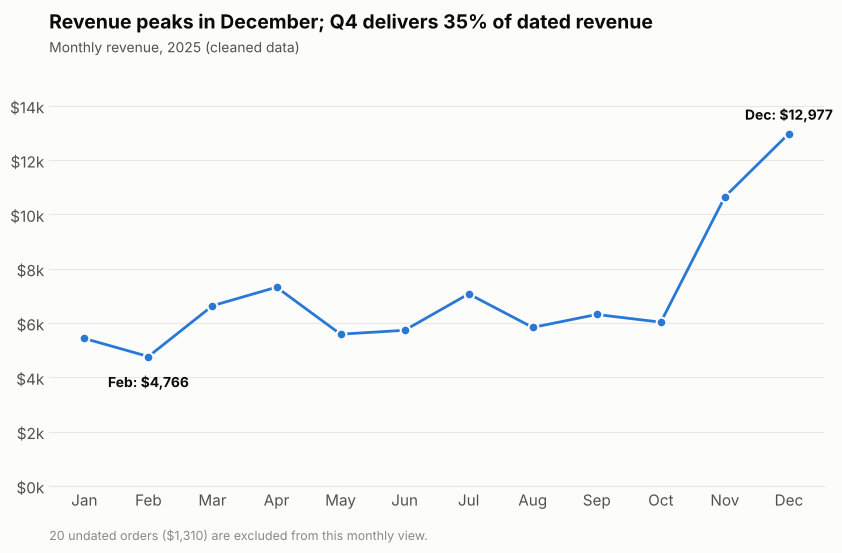

In [26]:
pk, lo = facts["peak_month"], facts["low_month"]
fig, ax = plt.subplots(figsize=(10, 5.4))
ax.plot(monthly["Label"], monthly["Revenue"], color=BLUE, linewidth=2, marker="o", markersize=7, markerfacecolor=BLUE,
        markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.set_ylim(0, monthly["Revenue"].max() * 1.18)
ax.yaxis.set_major_formatter(plt.FuncFormatter(usd_k))
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.spines["left"].set_visible(False)
for row, dy in ((pk, 10), (lo, -22)):
    ax.annotate(f"{row['Label']}: ${row['Revenue']:,.0f}", (row["Label"], row["Revenue"]), textcoords="offset points",
                xytext=(0, dy), ha="center", fontsize=10, color=INK, fontweight="bold")
titled(ax, f"Revenue peaks in {pk['Month_Start']:%B}; Q4 delivers {facts['q4_share']:.0%} of dated revenue",
       "Monthly revenue, 2025 (cleaned data)")
ax.text(0, -0.13, f"{kpis['Undated Orders']} undated orders (${kpis['Revenue on Undated Orders']:,.0f}) are excluded from this monthly view.",
        transform=ax.transAxes, fontsize=9, color=INK_3)
save(fig, "01_monthly_revenue_trend.png")

### Chart 2: Monthly order volume

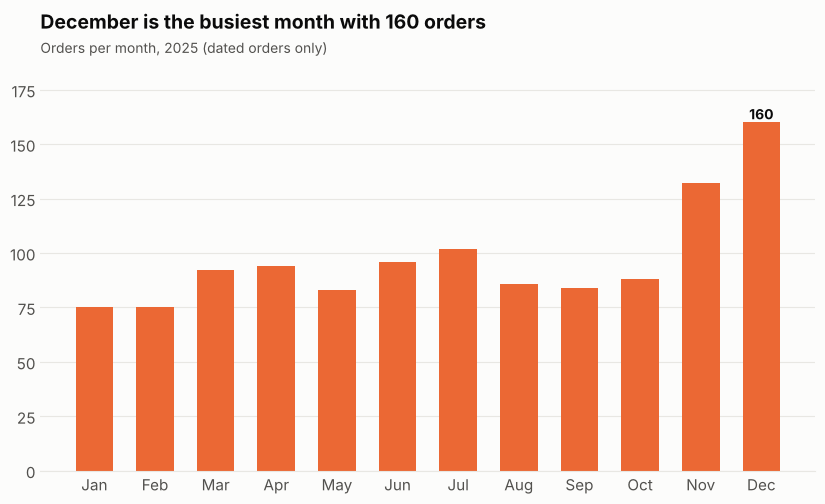

In [27]:
po = facts["peak_orders_month"]
fig, ax = plt.subplots(figsize=(10, 5.2))
bars = ax.bar(monthly["Label"], monthly["Orders"], color=ORANGE, width=0.62)
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.spines["left"].set_visible(False)
imax = int(monthly["Orders"].to_numpy().argmax())
ax.text(bars[imax].get_x() + bars[imax].get_width() / 2, po["Orders"] + 1.5, f"{int(po['Orders'])}", ha="center",
        fontsize=10, color=INK, fontweight="bold")
ax.set_ylim(0, monthly["Orders"].max() * 1.15)
titled(ax, f"{po['Month_Start']:%B} is the busiest month with {int(po['Orders'])} orders",
       "Orders per month, 2025 (dated orders only)")
save(fig, "02_monthly_orders.png")

### Charts 3 and 4: Best-selling products (by revenue and by units)

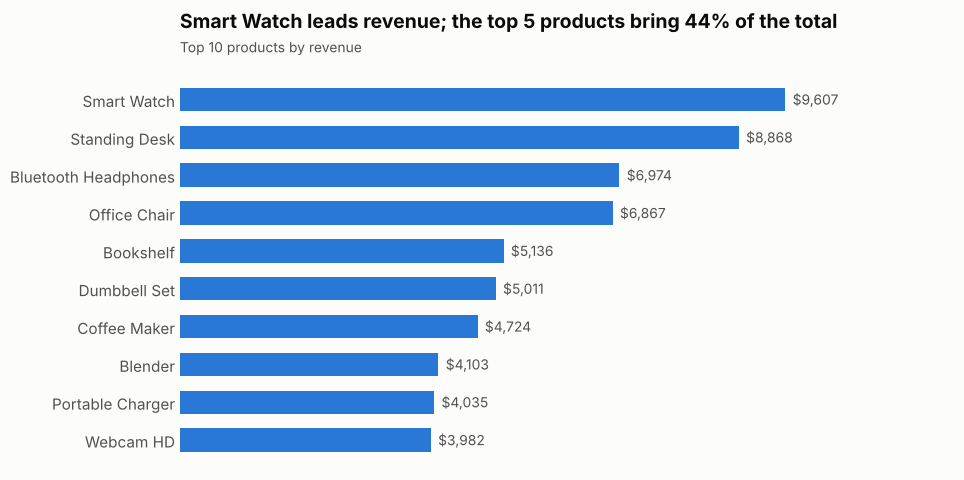

In [28]:
top_rev = known_products.sort_values("Revenue", ascending=False).head(10)
hbar(top_rev, "Product", "Revenue", BLUE,
     f"{top_rev.iloc[0]['Product']} leads revenue; the top 5 products bring {facts['top5_revenue_share']:.0%} of the total",
     "Top 10 products by revenue", lambda r: f"${r['Revenue']:,.0f}", "03_top_products_revenue.png")

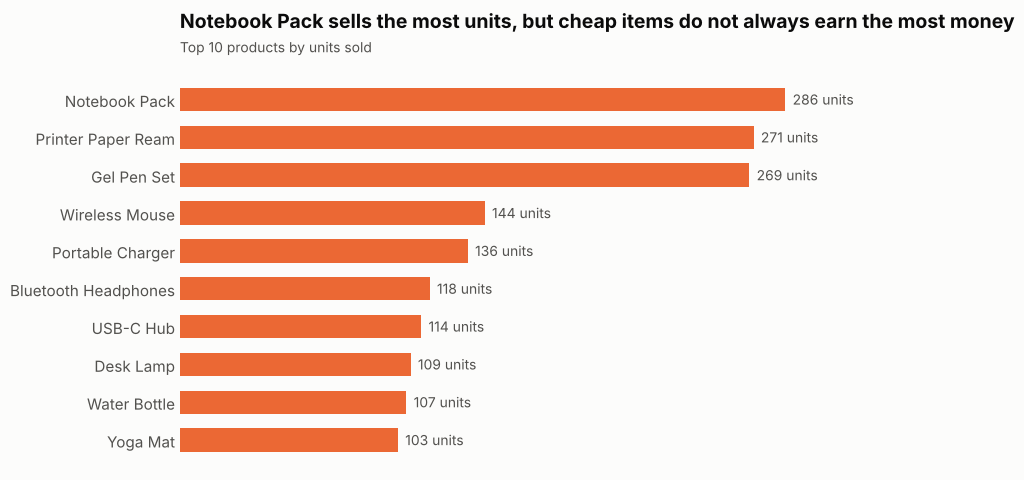

In [29]:
top_units = known_products.sort_values("Units", ascending=False).head(10)
hbar(top_units, "Product", "Units", ORANGE,
     f"{top_units.iloc[0]['Product']} sells the most units, but cheap items do not always earn the most money",
     "Top 10 products by units sold", lambda r: f"{int(r['Units']):,} units", "04_top_products_units.png")

### Chart 5: Category performance

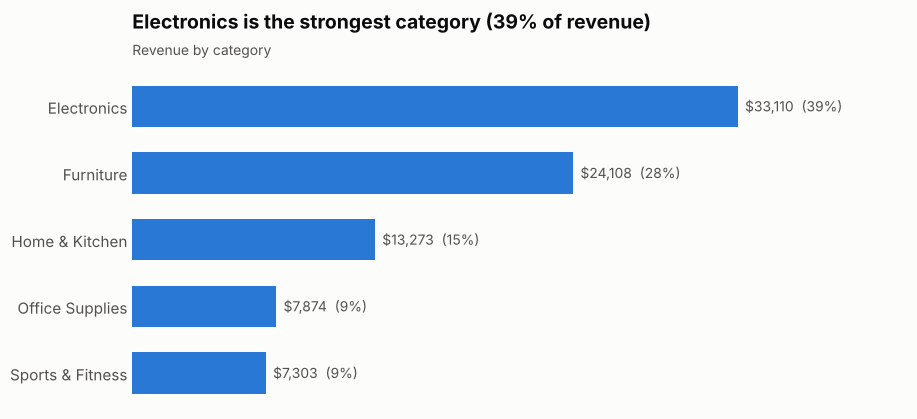

In [30]:
cp = category_perf
hbar(cp, "Category", "Revenue", BLUE, f"{cp.iloc[0]['Category']} is the strongest category ({cp.iloc[0]['Revenue_Share']:.0%} of revenue)",
     "Revenue by category", lambda r: f"${r['Revenue']:,.0f}  ({r['Revenue_Share']:.0%})", "05_revenue_by_category.png", figsize=(10, 4.4))

### Chart 6: Regional performance

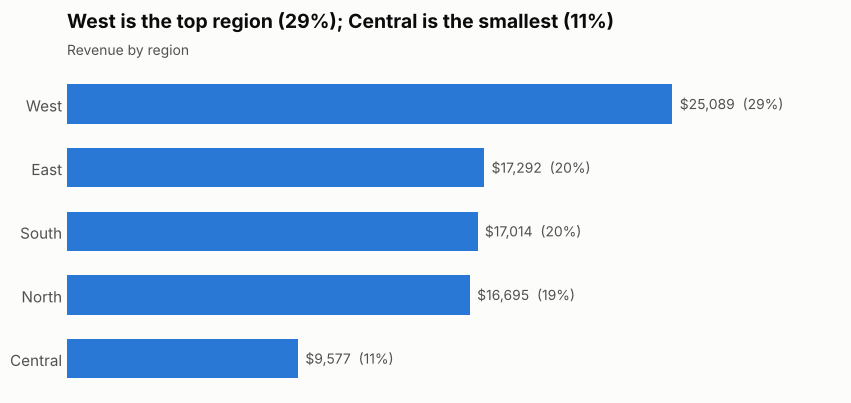

In [31]:
rp = region_perf
hbar(rp, "Region", "Revenue", BLUE,
     f"{rp.iloc[0]['Region']} is the top region ({rp.iloc[0]['Revenue_Share']:.0%}); {facts['low_region']['Region']} is the smallest ({facts['low_region']['Revenue_Share']:.0%})",
     "Revenue by region", lambda r: f"${r['Revenue']:,.0f}  ({r['Revenue_Share']:.0%})", "06_revenue_by_region.png", figsize=(10, 4.2))

### Chart 7: Payment method distribution

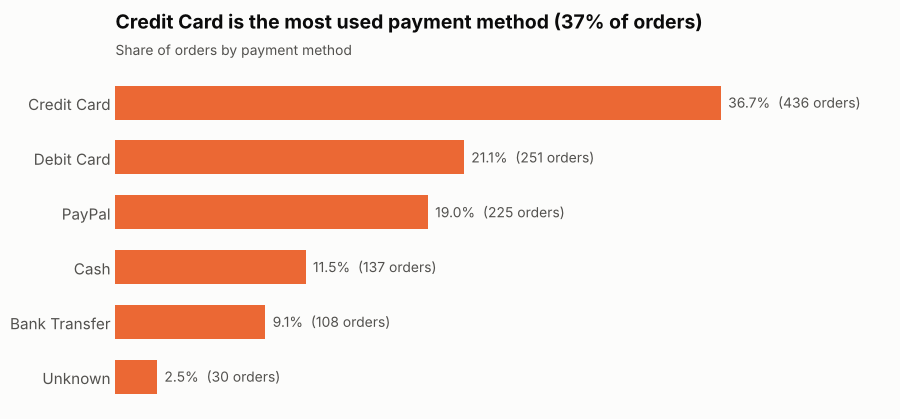

In [32]:
pp = payment_perf.sort_values("Orders", ascending=False).reset_index(drop=True)
hbar(pp, "Payment_Method", "Orders", ORANGE,
     f"{pp.iloc[0]['Payment_Method']} is the most used payment method ({pp.iloc[0]['Order_Share']:.0%} of orders)",
     "Share of orders by payment method", lambda r: f"{r['Order_Share']:.1%}  ({int(r['Orders']):,} orders)",
     "07_payment_method_distribution.png", figsize=(10, 4.4))

### Chart 8: Category x region heatmap

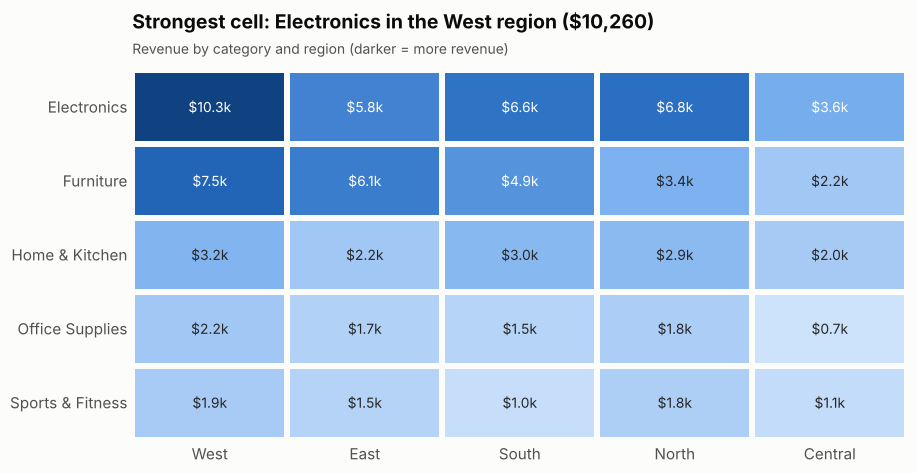

In [33]:
from matplotlib.colors import LinearSegmentedColormap

ramp = LinearSegmentedColormap.from_list("blue_ramp", ["#cde2fb", "#6da7ec", "#256abf", "#104281"])
fig, ax = plt.subplots(figsize=(10, 4.8))
labels = cat_region.map(lambda v: f"${v / 1000:,.1f}k")
sns.heatmap(cat_region, annot=labels, fmt="", cmap=ramp, linewidths=3, linecolor=SURFACE, cbar=False, ax=ax,
            annot_kws={"fontsize": 10})
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
best = cat_region.stack().idxmax()
titled(ax, f"Strongest cell: {best[0]} in the {best[1]} region (${cat_region.stack().max():,.0f})",
       "Revenue by category and region (darker = more revenue)")
save(fig, "08_category_region_heatmap.png")

### Chart 9: Distribution of order values

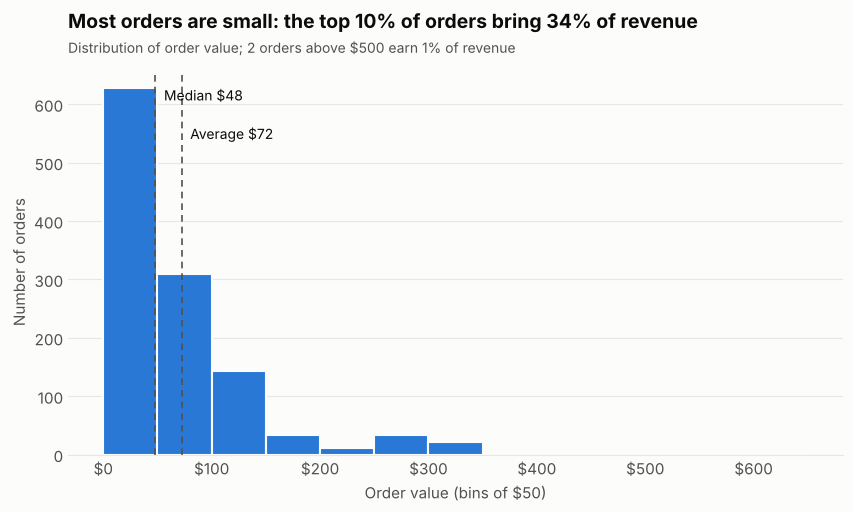

In [34]:
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.arange(0, order_values.max() + 50, 50)
ax.hist(sales["Total_Sales"], bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.spines["left"].set_visible(False)
ymax = ax.get_ylim()[1]
for value, name, dx in ((sales["Total_Sales"].median(), "Median", 8), (avg_order_value, "Average", 8)):
    ax.axvline(value, color=INK_2, linewidth=1.2, linestyle=(0, (4, 3)))
    ax.text(value + dx, ymax * (0.92 if name == "Median" else 0.82), f"{name} ${value:,.0f}", fontsize=10, color=INK)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_xlabel("Order value (bins of $50)")
ax.set_ylabel("Number of orders")
titled(ax, f"Most orders are small: the top 10% of orders bring {facts['top_decile_share']:.0%} of revenue",
       f"Distribution of order value; {facts['orders_over_500']} orders above $500 earn {facts['orders_over_500_revenue_share']:.0%} of revenue")
save(fig, "09_order_value_distribution.png")

### Chart 10: What was wrong with the raw data

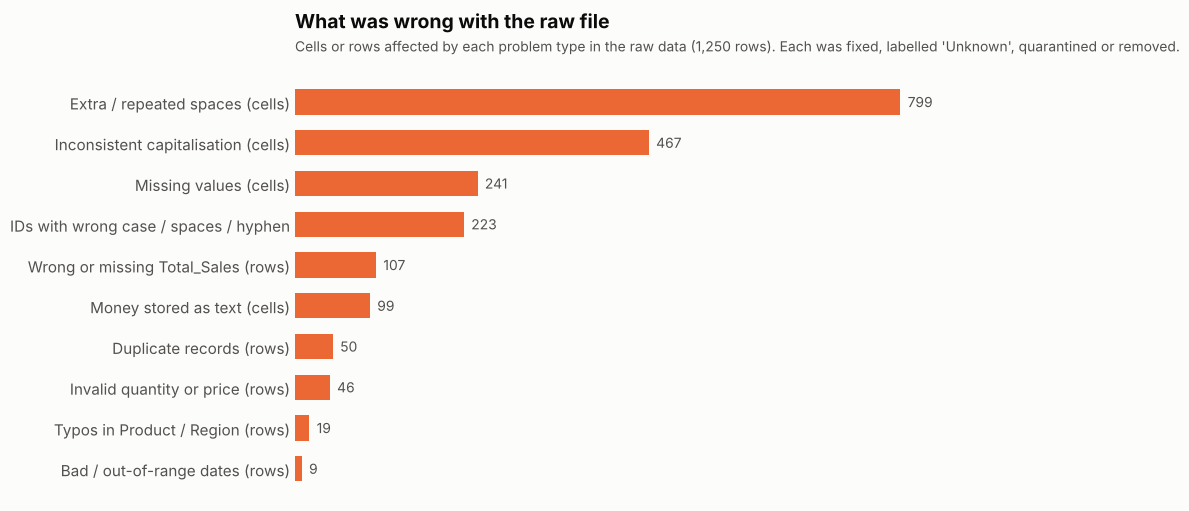

In [35]:
missing_cells = int(sum(audit["missing_by_col"].values()))
issues = pd.DataFrame({
    "Issue": ["Extra / repeated spaces (cells)", "Inconsistent capitalisation (cells)", "Missing values (cells)",
              "IDs with wrong case / spaces / hyphen", "Money stored as text (cells)", "Wrong or missing Total_Sales (rows)",
              "Duplicate records (rows)", "Invalid quantity or price (rows)", "Bad / out-of-range dates (rows)", "Typos in Product / Region (rows)"],
    "Count": [audit["space_cells"], sum(i["case_fixed"] for i in cat_info.values()), missing_cells, audit["id_format_cells"],
              audit["money_text_cells"], audit["total_mismatch"] + audit["missing_by_col"]["Total_Sales"],
              audit["dup_order_ids"], audit["qty_nonpositive"] + audit["qty_above_cap"] + audit["price_nonpositive"] + audit["price_implausible"],
              audit["date_unparseable"] + audit["date_out_of_range"], int(corrections["Rows"].sum())],
}).sort_values("Count", ascending=False).reset_index(drop=True)
hbar(issues, "Issue", "Count", ORANGE, "What was wrong with the raw file",
     f"Cells or rows affected by each problem type in the raw data ({len(raw):,} rows). Each was fixed, labelled 'Unknown', quarantined or removed.",
     lambda r: f"{int(r['Count']):,}", "10_data_quality_issues.png", figsize=(10, 5.6))

## 7. Cleaning decision log
One row per issue: what was found, how many records were touched, what was done and **why**. This table is exported to the
`Data_Quality` sheet of the workbook and summarised in the report.

In [36]:
flag_counts = cleaned["Cleaning_Flags"].str.get_dummies(sep=";").sum()
n_exact, n_hidden = int(raw_exact_dup.sum()), int(dup_mask.sum() - raw_exact_dup.sum())
n_total_wrong, n_total_missing = int(total_wrong.sum()), int(total_missing.sum())
n_returns = int(returns_like[quarantine_mask].sum())
n_zero = int((quarantined["Quantity_Reported"] == 0).sum())
n_zero_price = len(quarantined) - n_returns - n_zero

cleaning_log = pd.DataFrame([
    ("Exact duplicate rows", n_exact, "Removed", "Kept the first occurrence; logged in Flagged_Records",
     "Identical copies of the same order would double-count revenue."),
    ("Hidden duplicates (same order, different formatting)", n_hidden, "Removed", "Matched on the standardised Order_ID; verified all other fields were identical first",
     "Capitalisation, date format or '$' signs hid these from a plain duplicated() check."),
    ("Inconsistent capitalisation and extra spaces in text", audit["space_cells"], "Standardised", "Trimmed, collapsed repeated spaces, mapped variants to the most common spelling",
     "'west', ' WEST' and 'West' must be one group in every pivot table and chart."),
    ("Misspelled Product / Region values", int(corrections["Rows"].sum()), "Corrected", "Only values 1 edit away from exactly ONE frequent value; each fix is listed on the Data_Quality sheet",
     "A conservative rule avoids 'fixing' a real value into a wrong one."),
    ("Order_ID / Customer_ID with wrong case, spaces or missing hyphen", audit["id_format_cells"], "Standardised", "Re-formatted to ORD-##### and CUST-####",
     "Needed so that duplicates and repeat customers can be matched."),
    ("Dates written in 5 different formats", int((~date_missing).sum()), "Standardised", "Parsed to real datetimes; slash dates read as DAY/MONTH/YEAR (verified from the data)",
     "Text dates cannot be sorted or grouped by month."),
    ("Impossible, unreadable or out-of-range dates", int(date_unparseable.sum() + date_out_of_range.sum()), "Set to missing + flagged", "Not guessed (for example '2052' is not assumed to mean 2025)",
     "Inventing a date could put revenue in the wrong month; the order still counts in totals."),
    ("Missing Order_Date", int(date_missing.sum()), "Left blank + flagged", "No imputation", "No other column can tell us the date."),
    ("Prices / totals stored as text ('$29.99', '1,250.50')", audit["money_text_cells"], "Parsed to numbers", "Removed '$' and thousands commas",
     "Text cannot be summed."),
    ("Missing Category", int(flag_counts.get("Category_Imputed", 0)), "Filled from Product", "Each product belongs to exactly one category (verified)",
     "Provable from the same row, so this is not a guess."),
    ("Missing Region", int(flag_counts.get("Region_Imputed", 0)), "Filled from Customer_ID", "Used only customers whose other orders all share one region (verified)",
     "Provable from the same customer's other orders."),
    ("Missing Customer_ID", int(flag_counts.get("Customer_Unknown", 0)), "Labelled 'UNKNOWN'", "Not imputed", "Cannot be derived; the order still counts in revenue."),
    ("Missing Product", int(flag_counts.get("Product_Unknown", 0)), "Labelled 'Unknown Product'", "Not imputed", "Cannot be derived reliably (price alone is not unique)."),
    ("Missing Payment_Method", int(flag_counts.get("Payment_Unknown", 0)), "Labelled 'Unknown'", "Not imputed", "Guessing the most common method would invent data."),
    ("Invalid Quantity (negative, zero, missing, 999)", int(flag_counts.get("Qty_Recovered", 0)), "Recovered", "Quantity = Total_Sales / Unit_Price, accepted only if a whole number from 1 to 100",
     "The relationship Total = Quantity x Price gives proof when price and total are valid."),
    ("Invalid Unit_Price (negative, zero, 9999.99, decimal shift, missing)", int(flag_counts.get("Price_Recovered", 0)), "Recovered", "Unit_Price = Total_Sales / Quantity, accepted only within +-15% of the product's typical price",
     "The product's typical price is a second, independent piece of evidence."),
    ("Missing Unit_Price AND Total_Sales", int(flag_counts.get("Price_Imputed", 0)), "Estimated + flagged", "Used the product's typical (median) price",
     "Only estimate in the project; its revenue is reported separately in the KPI table."),
    ("Invalid numbers that cannot be repaired", len(quarantined), "Quarantined (excluded from analysis)",
     f"{n_returns} negative qty + negative total (possible returns), {n_zero} zero-quantity lines, {n_zero_price} zero-price lines; listed with reasons in Flagged_Records",
     "Not deleted silently: they are kept for the business to review. Netting possible returns needs a business rule."),
    ("Total_Sales missing or wrong", n_total_wrong + n_total_missing, "Recalculated", f"Total_Sales = Quantity x Unit_Price ({n_total_wrong} wrong, {n_total_missing} missing)",
     "A derived column must always agree with its inputs."),
], columns=["Issue", "Records", "Action", "Decision", "Rationale"])
display(cleaning_log)

,Issue,Records,Action,Decision,Rationale
0,Exact duplicate rows,28,Removed,Kept the first occurrence; logged in Flagged_Records,Identical copies of the same order would double-count revenue.
1,"Hidden duplicates (same order, different formatting)",22,Removed,Matched on the standardised Order_ID; verified all other fields were identical first,"Capitalisation, date format or '$' signs hid these from a plain duplicated() check."
2,Inconsistent capitalisation and extra spaces in text,799,Standardised,"Trimmed, collapsed repeated spaces, mapped variants to the most common spelling","'west', ' WEST' and 'West' must be one group in every pivot table and chart."
3,Misspelled Product / Region values,19,Corrected,Only values 1 edit away from exactly ONE frequent value; each fix is listed on the Data_Quality sheet,A conservative rule avoids 'fixing' a real value into a wrong one.
4,"Order_ID / Customer_ID with wrong case, spaces or missing hyphen",223,Standardised,Re-formatted to ORD-##### and CUST-####,Needed so that duplicates and repeat customers can be matched.
5,Dates written in 5 different formats,1238,Standardised,Parsed to real datetimes; slash dates read as DAY/MONTH/YEAR (verified from the data),Text dates cannot be sorted or grouped by month.
6,"Impossible, unreadable or out-of-range dates",9,Set to missing + flagged,Not guessed (for example '2052' is not assumed to mean 2025),Inventing a date could put revenue in the wrong month; the order still counts in totals.
7,Missing Order_Date,12,Left blank + flagged,No imputation,No other column can tell us the date.
8,"Prices / totals stored as text ('$29.99', '1,250.50')",99,Parsed to numbers,Removed '$' and thousands commas,Text cannot be summed.
9,Missing Category,24,Filled from Product,Each product belongs to exactly one category (verified),"Provable from the same row, so this is not a guess."


## 8. Export the Excel workbook
The workbook is built by `src/excel_export.py`. Summary and Analysis use **live formulas** that reference `Cleaned_Data`,
so any number can be traced inside Excel.

In [37]:
import importlib
import excel_export
importlib.reload(excel_export)

xlsx_file = excel_export.build_workbook(
    XLSX_PATH, raw, cleaned, flagged, dq_summary, recon, cleaning_log, corrections, CHART_DIR,
    product_to_category=product_to_category.to_dict())
print(f"Saved {xlsx_file.relative_to(ROOT)}  ({xlsx_file.stat().st_size / 1024:,.0f} KB)")
print("Sheets: Summary, Analysis, Cleaned_Data, Raw_Data, Data_Quality, Flagged_Records, Charts")

Saved output/sales_analysis.xlsx  (1,158 KB)
Sheets: Summary, Analysis, Cleaned_Data, Raw_Data, Data_Quality, Flagged_Records, Charts


## 9. Written report
The report is generated from the same variables as the tables and charts above, so its numbers cannot drift from the data.

In [38]:
def md_table(frame: pd.DataFrame, formats: dict | None = None) -> str:
    """Render a DataFrame as a GitHub-flavoured markdown table."""
    formats = formats or {}
    head = "| " + " | ".join(frame.columns) + " |"
    sep = "|" + "|".join("---:" if pd.api.types.is_numeric_dtype(frame[c]) else "---" for c in frame.columns) + "|"
    body = []
    for _, row in frame.iterrows():
        cells = [formats[c](row[c]) if c in formats else str(row[c]) for c in frame.columns]
        body.append("| " + " | ".join(cells) + " |")
    return "\n".join([head, sep] + body)


usd = lambda v: f"${v:,.2f}"
usd0 = lambda v: f"${v:,.0f}"
pct = lambda v: f"{v:.1%}"
num = lambda v: f"{int(v):,}"

nov, dec = monthly[monthly["Month_Start"].dt.month == 11].iloc[0], monthly[monthly["Month_Start"].dt.month == 12].iloc[0]
jan_oct_avg = monthly[monthly["Month_Start"].dt.month <= 10]["Revenue"].mean()
nov_dec_share = (nov["Revenue"] + dec["Revenue"]) / monthly["Revenue"].sum()
office = category_perf[category_perf["Category"] == "Office Supplies"].iloc[0]
two_top_cat = category_perf.head(2)
known_regions = region_perf[region_perf["Region"] != UNKNOWN["Region"]]
cards = payment_perf[payment_perf["Payment_Method"].isin(["Credit Card", "Debit Card"])]
top_unit_prod, top_rev_prod = facts["top_product_units"], facts["top_product_revenue"]

before_after_keys = ["Total rows", "Exact duplicate rows", "Hidden duplicates (same Order_ID, different formatting)",
                     "Rows with at least one missing value", "Cells with extra / repeated spaces", "Cells with inconsistent capitalisation",
                     "Misspelled values (typos)", "Distinct date formats", "Unreadable or out-of-range dates",
                     "Money values stored as text ($ or comma)", "Distinct Region spellings", "Distinct Product spellings",
                     "Quantity <= 0 or above cap", "Unit_Price <= 0 or implausibly high", "Total_Sales != Quantity x Unit_Price"]
dq_report = dq_summary[dq_summary["Metric"].isin(before_after_keys)]

report = f"""# Sales Data Cleaning and Exploratory Analysis: Report

> **Scope:** {len(raw):,} raw records exported from the company's sales systems, cleaned and analysed with Python and Pandas.
> The data is synthetic (generated with a fixed seed by `src/generate_raw_data.py`) but built to reproduce real export problems.
> Every number below is produced by `notebooks/sales_analysis.ipynb` from `data/cleaned_sales_data.csv`.

## 1. Executive summary

After cleaning, the company has **{num(total_orders)} valid orders** worth **{usd(total_revenue)}** in revenue
({kpis['First Order Date']:%d %b %Y} to {kpis['Last Order Date']:%d %b %Y}), an **average order value of {usd(avg_order_value)}**
and **{num(total_units)} units** sold.

| KPI | Value |
|---|---:|
| Total revenue | {usd(total_revenue)} |
| Total orders | {num(total_orders)} |
| Total units sold | {num(total_units)} |
| Average order value | {usd(avg_order_value)} |
| Median order value | {usd(kpis['Median Order Value'])} |
| Average units per order | {kpis['Average Units per Order']:.2f} |

**Key findings**

1. **Strong year-end seasonality.** November ({usd0(nov['Revenue'])}) and December ({usd0(dec['Revenue'])}) together earn {pct(nov_dec_share)} of dated revenue.
   Each is well above the Jan-Oct monthly average of {usd0(jan_oct_avg)} (November is {nov['Revenue'] / jan_oct_avg:.1f}x and December {dec['Revenue'] / jan_oct_avg:.1f}x that average).
2. **Revenue is driven by a few high-ticket lines.** {two_top_cat.iloc[0]['Category']} and {two_top_cat.iloc[1]['Category']} bring {pct(two_top_cat['Revenue_Share'].sum())} of revenue.
   The top 5 products ({', '.join(known_products.sort_values('Revenue', ascending=False).head(5)['Product'])}) bring {pct(facts['top5_revenue_share'])}.
3. **Volume and value tell different stories.** {office['Category']} is {pct(office['Order_Share'])} of orders but only {pct(office['Revenue_Share'])} of revenue
   (average order {usd(office['AOV'])}). {top_unit_prod['Product']} is the best seller by units ({num(top_unit_prod['Units'])}),
   while {top_rev_prod['Product']} leads by revenue ({usd0(top_rev_prod['Revenue'])}).
4. **West is the largest region** ({pct(facts['top_region']['Revenue_Share'])} of revenue); **{facts['low_region']['Region']} is the smallest** ({pct(facts['low_region']['Revenue_Share'])}).
   Average order values are similar across regions ({usd(known_regions['AOV'].min())} to {usd(known_regions['AOV'].max())}), so the gap comes from the number of orders, not their size.
5. **Cards dominate payments.** Credit and debit cards are {pct(cards['Order_Share'].sum())} of orders; {facts['top_payment']['Payment_Method']} alone is {pct(facts['top_payment']['Order_Share'])}.

## 2. Data quality: before and after

The raw file had **{audit['rows_with_missing']} of {len(raw):,} rows ({audit['rows_with_missing'] / len(raw):.0%}) with at least one missing value**, {audit['exact_dup_rows'] + audit['hidden_dup_rows']} duplicate records,
{audit['date_formats']} different date formats and a Total_Sales that did not equal Quantity x Unit_Price in {audit['total_mismatch']} rows (plus {audit['missing_by_col']['Total_Sales']} missing totals). The "After" column below was **measured on the cleaned file**, not assumed.

{md_table(dq_report[['Metric', 'Before', 'After']], {'Before': num, 'After': num})}

**Row reconciliation (every raw row is accounted for)**

{md_table(recon, {'Rows': num})}

Remaining missing values after cleaning: **{int(cleaned['Order_Date'].isna().sum())} undated orders** (the date cannot be derived, so it is left blank). All other gaps were either rebuilt from other columns or labelled `Unknown`.

## 3. Cleaning decisions

Rule of thumb: **fix** what can be proved from the same row/customer/product, **label** what cannot be derived, **quarantine** what is invalid and unrepairable. Nothing was deleted silently.

{md_table(cleaning_log, {'Records': num})}

### Records that were removed or set aside (not silently deleted)

* **{len(removed_dups)} duplicate rows** were removed (each points to the row it duplicates).
* **{len(quarantined)} invalid records** were quarantined and excluded from every KPI. They are listed with reasons in `data/flagged_records.csv` and on the `Flagged_Records` sheet.
  Their reported totals sum to {usd(quarantined['Total_Reported'].sum())} (negative = possible returns). If the business confirms they are valid returns, they can be netted off revenue.

{md_table(quarantined[['Raw_Row_Number', 'Order_ID', 'Product', 'Quantity_Reported', 'Unit_Price_Reported', 'Total_Reported', 'Reason']].rename(columns={'Raw_Row_Number': 'Raw row', 'Quantity_Reported': 'Qty', 'Unit_Price_Reported': 'Price', 'Total_Reported': 'Total'}).sort_values('Raw row').fillna(''), {'Raw row': num})}

### Sensitivity of the results to the cleaning choices

* Orders with an **estimated price** ({int(estimated_price_rows.sum())} rows) carry {usd(kpis['Revenue Using Estimated Prices'])} ({kpis['Revenue Using Estimated Prices'] / total_revenue:.1%} of revenue).
* **Undated orders** ({kpis['Undated Orders']} rows, {usd(kpis['Revenue on Undated Orders'])}, {kpis['Revenue on Undated Orders'] / total_revenue:.1%} of revenue) are in all totals but not in the monthly trend.
* **Unknown** product / payment / customer labels cover {int(flag_counts.get('Product_Unknown', 0))} / {int(flag_counts.get('Payment_Unknown', 0))} / {int(flag_counts.get('Customer_Unknown', 0))} orders.

## 4. Exploratory analysis

### Best-selling products (top 10 by revenue)

{md_table(known_products.sort_values('Revenue', ascending=False).head(10)[['Product', 'Category', 'Orders', 'Units', 'Revenue', 'Revenue_Share']].rename(columns={'Revenue_Share': 'Share'}), {'Orders': num, 'Units': num, 'Revenue': usd, 'Share': pct})}

Top 5 by units: {', '.join(f"{r.Product} ({int(r.Units)})" for r in known_products.sort_values('Units', ascending=False).head(5).itertuples())}.

### Categories

{md_table(category_perf[['Category', 'Orders', 'Units', 'Revenue', 'Revenue_Share', 'AOV']].rename(columns={'Revenue_Share': 'Share', 'AOV': 'Avg order'}), {'Orders': num, 'Units': num, 'Revenue': usd, 'Share': pct, 'Avg order': usd})}

### Monthly sales trend

{md_table(monthly[['Label', 'Orders', 'Units', 'Revenue', 'AOV', 'MoM_Growth']].rename(columns={'Label': 'Month', 'AOV': 'Avg order', 'MoM_Growth': 'MoM'}).assign(MoM=lambda d: d['MoM'].map(lambda v: '' if pd.isna(v) else f'{v:+.1%}')), {'Orders': num, 'Units': num, 'Revenue': usd, 'Avg order': usd})}

Dated orders: {num(monthly['Orders'].sum())} ({usd(monthly['Revenue'].sum())}). Undated: {kpis['Undated Orders']} ({usd(kpis['Revenue on Undated Orders'])}). Together they equal total revenue.

### Regions

{md_table(region_perf[['Region', 'Orders', 'Units', 'Revenue', 'Revenue_Share', 'AOV']].rename(columns={'Revenue_Share': 'Share', 'AOV': 'Avg order'}), {'Orders': num, 'Units': num, 'Revenue': usd, 'Share': pct, 'Avg order': usd})}

### Payment methods

{md_table(payment_perf[['Payment_Method', 'Orders', 'Order_Share', 'Revenue', 'AOV']].rename(columns={'Payment_Method': 'Payment method', 'Order_Share': 'Share of orders', 'AOV': 'Avg order'}), {'Orders': num, 'Share of orders': pct, 'Revenue': usd, 'Avg order': usd})}

### Other observations

* The top 10% of orders ({top_decile_n} orders) account for {pct(facts['top_decile_share'])} of revenue; only {facts['orders_over_500']} orders exceed $500.
* {pct(facts['repeat_customer_share'])} of the {facts['known_customers_n']} identifiable customers placed two or more orders.

## 5. Charts

All charts are saved in `output/charts/` (and embedded in the workbook's `Charts` sheet).

| # | Chart | File |
|---|---|---|
| 1 | Monthly revenue trend | `01_monthly_revenue_trend.png` |
| 2 | Monthly order volume | `02_monthly_orders.png` |
| 3 | Top products by revenue | `03_top_products_revenue.png` |
| 4 | Top products by units | `04_top_products_units.png` |
| 5 | Revenue by category | `05_revenue_by_category.png` |
| 6 | Revenue by region | `06_revenue_by_region.png` |
| 7 | Payment method distribution | `07_payment_method_distribution.png` |
| 8 | Category x region heatmap | `08_category_region_heatmap.png` |
| 9 | Order value distribution | `09_order_value_distribution.png` |
| 10 | Data quality issues found | `10_data_quality_issues.png` |

![Monthly revenue](../output/charts/01_monthly_revenue_trend.png)
![Top products](../output/charts/03_top_products_revenue.png)

## 6. Recommendations

These follow from the findings above; they are suggestions to test, not proven causal effects.

1. **Plan inventory, staffing and promotions around November-December.** Demand in those two months is {nov['Revenue'] / jan_oct_avg:.1f}x to {dec['Revenue'] / jan_oct_avg:.1f}x a typical Jan-Oct month.
2. **Protect the high-ticket lines** ({top_rev_prod['Product']}, {known_products.sort_values('Revenue', ascending=False).iloc[1]['Product']}): they generate the most revenue from relatively few orders, so stock-outs would be costly.
3. **Raise the value of Office Supplies orders** (e.g. bundles or add-ons): they are {pct(office['Order_Share'])} of orders but {pct(office['Revenue_Share'])} of revenue.
4. **Investigate the {facts['low_region']['Region']} region.** Its order values are in line with other regions, so the shortfall is in order count. The data cannot say why (customer base, marketing, stores); that needs business input.
5. **Fix data capture at the source.** Make Order_ID, date, product, quantity and price mandatory; enforce one date format and a pick-list for Region / Payment_Method / Category; reject negative quantities and prices; calculate Total_Sales in the system instead of typing it; prevent re-imports that duplicate orders.

## 7. Assumptions and limitations

* One row is one order line, so *orders* equal distinct `Order_ID`s; currency is assumed to be USD; the data covers calendar year 2025.
* Slash dates are read as DAY/MONTH/YEAR. The first number reaches 31 while the second never exceeds 12, which rules out month-first.
* Possible returns (negative quantity and negative total) were quarantined, not netted; their treatment needs a business rule.
* Prices rebuilt from `Total / Quantity` are trusted only if they fall within +-15% of the product's usual price; a missing price with no usable total uses the product's median price (flagged).
* The dataset is a single year, so year-over-year growth cannot be measured, and seasonality is observed once.
* With a synthetic dataset the patterns (for example Q4 peak) are designed into the generator; the *method* is what this project demonstrates.

## 8. Reproducibility and validation

Run `python src/generate_raw_data.py`, then execute `notebooks/sales_analysis.ipynb` top to bottom. The last notebook section recomputes every KPI independently
from `data/cleaned_sales_data.csv`, checks the Excel workbook's stored values against it, and verifies that this report quotes the same numbers.
"""
REPORT_MD.write_text(report, encoding="utf-8")
print(f"Saved {REPORT_MD.relative_to(ROOT)}  ({len(report.splitlines())} lines)")

Saved reports/analysis_report.md  (240 lines)


## 10. Quality assurance: do the reported numbers match the cleaned data?
Everything is re-read **from the files on disk** and recomputed independently of the variables used above.

In [39]:
import openpyxl

qa = pd.read_csv(CLEAN_CSV, parse_dates=["Order_Date"])
checks = []


def check(name: str, ok: bool, detail: str = ""):
    checks.append((name, bool(ok), detail))


# --- cleaned dataset integrity ------------------------------------------------------------------
check("Order_ID is unique", qa["Order_ID"].is_unique)
check("No duplicate rows", not qa.duplicated().any())
check("Quantity is a whole number between 1 and 100", qa["Quantity"].between(1, MAX_QTY).all())
check("Unit_Price is positive", (qa["Unit_Price"] > 0).all())
check("Total_Sales == Quantity x Unit_Price (to the cent) for every row",
      ((qa["Quantity"] * qa["Unit_Price"]).round(2) - qa["Total_Sales"]).abs().max() < 0.005)
check("No missing values except undated orders", qa.drop(columns=["Order_Date", "Cleaning_Flags"]).notna().all().all())
check("Text columns have no leading/trailing/double spaces",
      not qa[TEXT_COLS + ["Customer_ID", "Order_ID"]].apply(lambda s: s.str.contains(r"^\s|\s$|\s{2}")).any().any())
check("Region / Payment / Category value sets are the expected ones",
      set(qa["Region"]) <= {"North", "South", "East", "West", "Central", "Unknown"} and
      set(qa["Payment_Method"]) <= {"Credit Card", "Debit Card", "PayPal", "Cash", "Bank Transfer", "Unknown"} and qa["Category"].nunique() == 5)
check("Dates are within 2025", qa["Order_Date"].dropna().dt.year.eq(2025).all())

# --- row reconciliation -----------------------------------------------------------------------------
fl = pd.read_csv(FLAGGED_CSV)
check("raw rows = cleaned + duplicates removed + quarantined", len(raw) == len(qa) + (fl["Issue_Type"] == "Duplicate removed").sum() + fl["Issue_Type"].str.startswith("Quarantined").sum())
check("Every flagged record has a reason", fl["Reason"].notna().all() and (fl["Reason"].str.len() > 10).all())

# --- KPIs recomputed from the CSV match what was reported ---------------------------------------------
check("Total revenue matches", abs(qa["Total_Sales"].sum() - total_revenue) < 0.005, f"{qa['Total_Sales'].sum():,.2f}")
check("Total orders matches", qa["Order_ID"].nunique() == total_orders, str(qa["Order_ID"].nunique()))
check("Total units matches", qa["Quantity"].sum() == total_units, str(qa["Quantity"].sum()))
check("Average order value matches", abs(qa["Total_Sales"].sum() / qa["Order_ID"].nunique() - avg_order_value) < 1e-9)
for name, table, col in (("Product", product_perf, "Product"), ("Category", category_perf, "Category"),
                         ("Region", region_perf, "Region"), ("Payment_Method", payment_perf, "Payment_Method")):
    fresh = qa.groupby(col)["Total_Sales"].sum()
    ok = np.allclose(table.set_index(col)["Revenue"].sort_index().to_numpy(), fresh.sort_index().to_numpy()) and abs(table["Revenue"].sum() - total_revenue) < 0.005
    check(f"{name} table revenue matches and sums to total", ok)
fresh_m = qa.dropna(subset=["Order_Date"]).groupby(qa["Order_Date"].dt.to_period("M"))["Total_Sales"].sum()
check("Monthly revenue matches", np.allclose(monthly["Revenue"].to_numpy(), fresh_m.to_numpy()))
check("Monthly + undated revenue = total revenue", abs(fresh_m.sum() + qa.loc[qa["Order_Date"].isna(), "Total_Sales"].sum() - total_revenue) < 0.005)

# --- Excel workbook -------------------------------------------------------------------------------------
wb_vals = openpyxl.load_workbook(XLSX_PATH, data_only=True)
check("Workbook has the required sheets", {"Raw_Data", "Cleaned_Data", "Summary", "Analysis"} <= set(wb_vals.sheetnames), ", ".join(wb_vals.sheetnames))
check("Raw_Data has every raw row", wb_vals["Raw_Data"].max_row == len(raw) + 1)
check("Cleaned_Data has every cleaned row", wb_vals["Cleaned_Data"].max_row == len(qa) + 1)
summary_ws = wb_vals["Summary"]
xl_kpi = {summary_ws.cell(r, 1).value: summary_ws.cell(r, 2).value for r in range(6, 18)}
check("Excel Summary: Total Revenue", abs(xl_kpi["Total Revenue"] - total_revenue) < 0.005)
check("Excel Summary: Total Orders", xl_kpi["Total Orders"] == total_orders)
check("Excel Summary: Total Units Sold", xl_kpi["Total Units Sold"] == total_units)
check("Excel Summary: Average Order Value", abs(xl_kpi["Average Order Value"] - avg_order_value) < 0.005)
check("Excel Summary: Unique Customers", xl_kpi["Unique Customers (known IDs)"] == kpis["Unique Customers (known IDs)"])

# --- report and charts --------------------------------------------------------------------------------------
report_text = REPORT_MD.read_text(encoding="utf-8")
for label, token in (("revenue", usd(total_revenue)), ("orders", num(total_orders)), ("units", num(total_units)), ("AOV", usd(avg_order_value))):
    check(f"Report quotes the correct {label}", token in report_text, token)
check("At least 5 charts saved", len(list(CHART_DIR.glob("*.png"))) >= 5, f"{len(list(CHART_DIR.glob('*.png')))} charts")

result = pd.DataFrame(checks, columns=["Check", "Passed", "Detail"])
result["Passed"] = result["Passed"].map({True: "PASS", False: "FAIL"})
display(result)
assert (result["Passed"] == "PASS").all(), "Some QA checks failed"
print(f"\nALL {len(result)} QA CHECKS PASSED")

,Check,Passed,Detail
0,Order_ID is unique,PASS,
1,No duplicate rows,PASS,
2,Quantity is a whole number between 1 and 100,PASS,
3,Unit_Price is positive,PASS,
4,Total_Sales == Quantity x Unit_Price (to the cent) for every row,PASS,
5,No missing values except undated orders,PASS,
6,Text columns have no leading/trailing/double spaces,PASS,
7,Region / Payment / Category value sets are the expected ones,PASS,
8,Dates are within 2025,PASS,
9,raw rows = cleaned + duplicates removed + quarantined,PASS,



ALL 34 QA CHECKS PASSED
